### MGM I2I

In [1]:
import os
import sys
from pathlib import Path
from google.colab import userdata

import copy
import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset, random_split
from torchvision import datasets, transforms
from torchvision.transforms.functional import resize, InterpolationMode
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

In [2]:
!pip install torchmetrics -q

## 0) Loading different data

#### 0.1) CelebA

In [3]:
# mount drive for the sake of checkpoints

from google.colab import drive
drive.mount('/content/drive')

CHECKPOINTS_PATH = "/content/drive/MyDrive/AI_Notebooks/MGM/checkpoints"
FOLDER_PATH = "/content/drive/MyDrive/AI_Notebooks/MGM"

sys.path.insert(0, FOLDER_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load secret directly into Colab environment
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

In [ ]:
# Download & unzip directly
!kaggle datasets download -d jessicali9530/celeba-dataset -p ./celeba_raw --unzip

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
100% 1.33G/1.33G [00:18<00:00, 76.6MB/s]



In [ ]:
class KaggleCelebADataset(Dataset):
    def __init__(self, img_dir, num_samples=12000, transform=None):
        self.img_dir = img_dir

        # Verify the folder path
        if not os.path.exists(img_dir):
            raise FileNotFoundError(f"Directory {img_dir} not found. Check Kaggle download extraction path!")

        all_files = sorted(os.listdir(img_dir))
        # Filter for image files and pick the first num_samples
        self.img_files = [f for f in all_files if f.endswith(('.jpg', '.jpeg', '.png'))][:num_samples]
        self.transform = transform
        print(f"Dataset initialized: Loaded {len(self.img_files)} images from local storage.")

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image

In [ ]:
def paired_collate_fn(batch):
    # Target HR images: [N, 3, 128, 128], in [0, 1].
    x_1 = torch.stack(batch)

    # HR -> actual LR observation.
    x_0_lr = resize(
        x_1,
        [32, 32],
        interpolation=InterpolationMode.BICUBIC,
        antialias=True,
    ).clamp(0.0, 1.0)

    # Upsample LR to match the current generator input size.
    x_0 = resize(
        x_0_lr,
        [128, 128],
        interpolation=InterpolationMode.BICUBIC,
        antialias=True,
    ).clamp(0.0, 1.0)

    return x_0, x_1

In [ ]:
def get_celeba_dataloaders(
    data_dir="./celeba_raw/img_align_celeba/img_align_celeba",
    batch_size=32,
    num_samples=10_000,
    num_val_samples=2_000,
    num_workers=2,
    seed=42,
):
    transform = transforms.Compose([
        transforms.CenterCrop(178),
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        # No Normalize: keep targets in [0, 1].
    ])

    # Preserve your fallback path check.
    if not os.path.exists(data_dir):
        alt_dir = "./celeba_raw/img_align_celeba"
        if os.path.exists(alt_dir):
            data_dir = alt_dir

    total_samples = num_samples + num_val_samples

    dataset = KaggleCelebADataset(
        data_dir,
        num_samples=total_samples,
        transform=transform,
    )

    if len(dataset) < total_samples:
        raise ValueError(
            f"Need {total_samples:,} images, but only "
            f"{len(dataset):,} were loaded."
        )

    train_dataset, val_dataset = random_split(
        dataset,
        [num_samples, num_val_samples],
        generator=torch.Generator().manual_seed(seed),
    )

    # Verify that no image belongs to both subsets.
    assert set(train_dataset.indices).isdisjoint(
        val_dataset.indices
    )

    loader_kwargs = dict(
        batch_size=batch_size,
        collate_fn=paired_collate_fn,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(num_workers > 0),
    )

    train_dataloader = DataLoader(
        train_dataset,
        shuffle=True,
        drop_last=False,
        generator=torch.Generator().manual_seed(seed + 1),
        **loader_kwargs,
    )

    val_dataloader = DataLoader(
        val_dataset,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    print(f"Training images:   {len(train_dataset):,}")
    print(f"Validation images: {len(val_dataset):,}")
    print(f"Training batches:  {len(train_dataloader):,}")
    print(f"Validation batches:{len(val_dataloader):,}")

    return train_dataloader, val_dataloader

In [ ]:
# Create dataloaders
train_loader, val_loader = get_celeba_dataloaders(
    data_dir="./celeba_raw/img_align_celeba/img_align_celeba",
    batch_size=32,
    num_samples=10_000,
    num_val_samples=2_000,
    num_workers=2,
    seed=42
)

Dataset initialized: Loaded 12000 images from local storage.
Training images:   10,000
Validation images: 2,000
Training batches:  313
Validation batches:63


In [ ]:
# Fetch 1 batch from the Kaggle dataset
x0_batch, x1_batch = next(iter(train_loader))
print(f"Condition Input x0 (LR) Shape: {x0_batch.shape}")
print(f"Target Output    x1 (HR) Shape: {x1_batch.shape}")

Condition Input x0 (LR) Shape: torch.Size([32, 3, 128, 128])
Target Output    x1 (HR) Shape: torch.Size([32, 3, 128, 128])


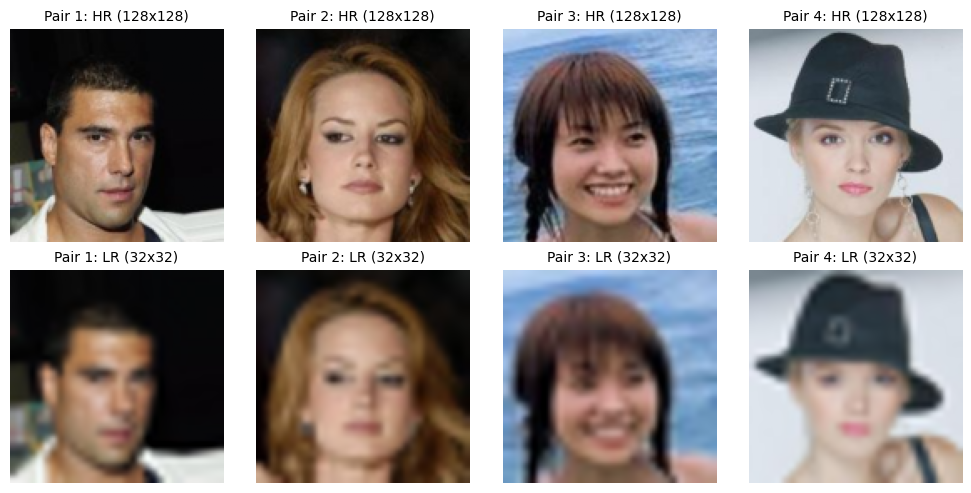

In [ ]:
# # 2. Function to un-normalize image tensors from [-1, 1] back to [0, 1]
# def unnormalize(tensor):
#     return (tensor * 0.5 + 0.5).clamp(0, 1)

# 3. Create a 2-row x 4-column subplot grid
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i in range(4):
    # Convert (C, H, W) PyTorch tensor to (H, W, C) for Matplotlib
    # hr_img = unnormalize(x1_batch[i]).permute(1, 2, 0).cpu().numpy()
    # lr_img = unnormalize(x0_batch[i]).permute(1, 2, 0).cpu().numpy()
    hr_img = x1_batch[i].permute(1, 2, 0).cpu().numpy()
    lr_img = x0_batch[i].permute(1, 2, 0).cpu().numpy()

    # Row 1: High Resolution (Target x1)
    axes[0, i].imshow(hr_img)
    axes[0, i].set_title(f"Pair {i+1}: HR (128x128)", fontsize=10)
    axes[0, i].axis("off")

    # Row 2: Low Resolution (Input x0)
    axes[1, i].imshow(lr_img)
    axes[1, i].set_title(f"Pair {i+1}: LR (32x32)", fontsize=10)
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

#### 0.2) MNIST

In [4]:
class MNISTPairedDataset(torch.utils.data.Dataset):
    def __init__(self, root="./data", train=True):
        self.dataset = datasets.MNIST(
            root=root,
            train=train,
            download=True,
            transform=transforms.ToTensor(),
        )

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]  # [1, 28, 28]

        # Target: grayscale digit at 64 x 64.
        x_1 = resize(
            image,
            [64, 64],
            interpolation=InterpolationMode.BICUBIC,
            antialias=True,
        ).clamp(0.0, 1.0)

        # Degrade the target to 10 x 10.
        x_lr = resize(
            x_1,
            [10, 10],
            interpolation=InterpolationMode.BICUBIC,
            antialias=True,
        ).clamp(0.0, 1.0)

        # Upsample back to the target dimensions.
        x_0 = resize(
            x_lr,
            [64, 64],
            interpolation=InterpolationMode.BICUBIC,
            antialias=True,
        ).clamp(0.0, 1.0)

        return x_0, x_1

In [5]:
train_dataset = MNISTPairedDataset(train=True)
val_dataset = MNISTPairedDataset(train=False)

mnist_train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)

mnist_val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

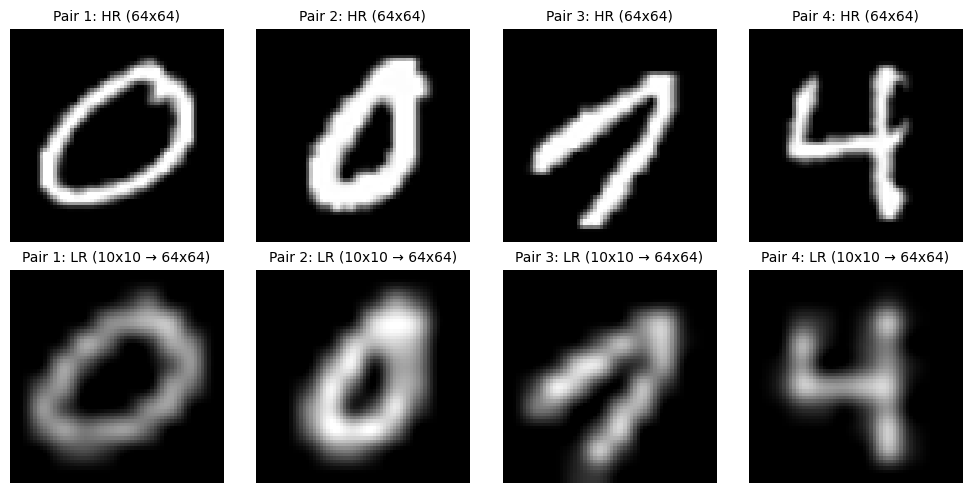

In [ ]:
x0_batch, x1_batch = next(iter(mnist_train_loader))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i in range(4):
    # MNIST images are grayscale: (C, H, W) -> (H, W)
    hr_img = x1_batch[i, 0].cpu().numpy()
    lr_img = x0_batch[i, 0].cpu().numpy()

    # Row 1: High Resolution (Target x1)
    axes[0, i].imshow(hr_img, cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Pair {i+1}: HR (64x64)", fontsize=10)
    axes[0, i].axis("off")

    # Row 2: Low Resolution (Input x0, upsampled to 64x64)
    axes[1, i].imshow(lr_img, cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(f"Pair {i+1}: LR (10x10 → 64x64)", fontsize=10)
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## 1) Initial trial (not very corect)

#### 1.1) Models for MGM -> generator & critic

In [ ]:
class CelebAUNetGenerator(nn.Module):
    """
    Direct One-Step Generator mapping Low-Res x0 (3x128x128) -> High-Res x1_hat (3x128x128).
    """
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.SiLU())
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.GroupNorm(8, 128), nn.SiLU())
        self.enc3 = nn.Sequential(nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.GroupNorm(8, 256), nn.SiLU())

        # Bottleneck
        self.bottleneck = nn.Sequential(nn.Conv2d(256, 256, 3, padding=1), nn.GroupNorm(8, 256), nn.SiLU())

        # Decoder
        self.dec3 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.GroupNorm(8, 128), nn.SiLU())
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(256, 64, 4, stride=2, padding=1), nn.GroupNorm(8, 64), nn.SiLU())

        self.out = nn.Sequential(nn.Conv2d(128, out_channels, 3, padding=1), nn.Tanh())

    def forward(self, x0):
        e1 = self.enc1(x0)                             # [B, 64, 128, 128]
        e2 = self.enc2(e1)                             # [B, 128, 64, 64]
        e3 = self.enc3(e2)                             # [B, 256, 32, 32]

        b = self.bottleneck(e3)                        # [B, 256, 32, 32]

        d3 = self.dec3(b)                              # [B, 128, 64, 64]
        d2 = self.dec2(torch.cat([d3, e2], dim=1))     # [B, 64, 128, 128]

        x1_hat = self.out(torch.cat([d2, e1], dim=1))  # [B, 3, 128, 128]
        return x1_hat

In [ ]:
class CelebACriticField(nn.Module):
    """
    Learned Displacement/Vector Field f_psi(t, x_t, x0).
    Evaluates interpolations conditioned on state x_t, source x0, and time t.
    """
    def __init__(self):
        super().__init__()
        # Concatenated input: state x_t (3 ch) + source x0 (3 ch) = 6 ch
        self.init_conv = nn.Conv2d(6, 64, 3, padding=1)
        self.time_embed = nn.Sequential(nn.Linear(1, 64), nn.SiLU())

        self.net = nn.Sequential(
            nn.Conv2d(64, 128, 4, stride=2, padding=1),       # 64x64
            nn.GroupNorm(8, 128),
            nn.SiLU(),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),      # 32x32
            nn.GroupNorm(8, 256),
            nn.SiLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 64x64
            nn.GroupNorm(8, 128),
            nn.SiLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 128x128
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.Conv2d(64, 3, 3, padding=1)
        )

    def forward(self, t, x_t, x0):
        h = self.init_conv(torch.cat([x_t, x0], dim=1))
        t_emb = self.time_embed(t.view(-1, 1)).unsqueeze(-1).unsqueeze(-1)
        h = h + t_emb
        return self.net(h)

#### 1.2) Training pipeline

In [ ]:
def train_mgm_celeba(
    epochs=5,
    batch_size=32,
    num_samples=10000,
    lr=2e-4,
    lambda_l1=0.5
):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Starting MGM CelebA-128 Training on: {device}")

    # DataLoader & Models
    dataloader = get_celeba_dataloader(batch_size=batch_size, num_samples=num_samples)
    generator = CelebAUNetGenerator().to(device)
    critic = CelebACriticField().to(device)

    opt_g = optim.AdamW(generator.parameters(), lr=lr, betas=(0.5, 0.9))
    opt_c = optim.AdamW(critic.parameters(), lr=lr, betas=(0.5, 0.9))

    l1_loss = nn.L1Loss()
    mse_loss = nn.MSELoss()

    for epoch in range(epochs):
        generator.train()
        critic.train()

        for step, (x0, x1) in enumerate(dataloader):
            x0, x1 = x0.to(device), x1.to(device)
            B = x0.shape[0]

            # Sample random interpolation time t uniformly in [0, 0.5] (Integrated Midpoint Logic)
            t = torch.rand((B,), device=device) * 0.5
            t_expand = t.view(B, 1, 1, 1)

            # -------------------------------------------------------------
            # STEP 1: Train Critic / Displacement Field f_psi
            # -------------------------------------------------------------
            opt_c.zero_grad()

            with torch.no_grad():
                x1_hat = generator(x0)  # Current 1-step generator estimate

            # True straight trajectory interpolation (x0 -> x1)
            x_t_real = (1 - t_expand) * x0 + t_expand * x1
            v_target_real = x1 - x0

            # Generated straight trajectory interpolation (x0 -> x1_hat)
            x_t_fake = (1 - t_expand) * x0 + t_expand * x1_hat
            v_target_fake = x1_hat - x0

            # Evaluate critic displacement field predictions
            v_pred_real = critic(t, x_t_real, x0)
            v_pred_fake = critic(t, x_t_fake, x0)

            # Critic MSE Loss on both real and generated displacement fields
            loss_c = mse_loss(v_pred_real, v_target_real) + mse_loss(v_pred_fake, v_target_fake)
            loss_c.backward()
            opt_c.step()

            # -------------------------------------------------------------
            # STEP 2: Train Generator G_theta
            # -------------------------------------------------------------
            opt_g.zero_grad()

            x1_hat = generator(x0)
            x_t_fake = (1 - t_expand) * x0 + t_expand * x1_hat

            # Midpoint Divergence: Match generated displacement field to real target displacement
            v_field_fake = critic(t, x_t_fake, x0)
            loss_mgm = torch.mean((v_field_fake - (x1 - x0)) ** 2)

            # Auxiliary L1 loss for fast structural convergence
            loss_aux = l1_loss(x1_hat, x1)

            loss_g = loss_mgm + lambda_l1 * loss_aux
            loss_g.backward()
            opt_g.step()

            # Logging
            if step % 50 == 0:
                print(f"Epoch [{epoch+1}/{epochs}] Step [{step}/{len(dataloader)}] "
                      f"| Loss C: {loss_c.item():.4f} | Loss G: {loss_g.item():.4f} (MGM: {loss_mgm.item():.4f}, L1: {loss_aux.item():.4f})")

    print("CelebA MGM Training Complete!")
    return generator

In [ ]:
trained_generator = train_mgm_celeba(epochs=5, num_samples=10000)

Starting MGM CelebA-128 Training on: cuda
Dataset initialized: Loaded 10000 images from local storage.
Epoch [1/5] Step [0/313] | Loss C: 0.6514 | Loss G: 0.4511 (MGM: 0.1773, L1: 0.5476)
Epoch [1/5] Step [50/313] | Loss C: 0.0214 | Loss G: 0.0516 (MGM: 0.0104, L1: 0.0825)
Epoch [1/5] Step [100/313] | Loss C: 0.0169 | Loss G: 0.0454 (MGM: 0.0100, L1: 0.0708)
Epoch [1/5] Step [150/313] | Loss C: 0.0127 | Loss G: 0.0425 (MGM: 0.0099, L1: 0.0652)
Epoch [1/5] Step [200/313] | Loss C: 0.0107 | Loss G: 0.0378 (MGM: 0.0073, L1: 0.0610)
Epoch [1/5] Step [250/313] | Loss C: 0.0084 | Loss G: 0.0394 (MGM: 0.0079, L1: 0.0630)
Epoch [1/5] Step [300/313] | Loss C: 0.0072 | Loss G: 0.0359 (MGM: 0.0076, L1: 0.0565)
Epoch [2/5] Step [0/313] | Loss C: 0.0060 | Loss G: 0.0355 (MGM: 0.0076, L1: 0.0558)
Epoch [2/5] Step [50/313] | Loss C: 0.0047 | Loss G: 0.0312 (MGM: 0.0062, L1: 0.0499)
Epoch [2/5] Step [100/313] | Loss C: 0.0042 | Loss G: 0.0299 (MGM: 0.0053, L1: 0.0491)
Epoch [2/5] Step [150/313] | Loss

#### 1.3) Test the model

In [ ]:
# 2. Evaluation and visualization function
def evaluate_and_plot_mgm(generator, dataloader, device='cuda'):
    generator.eval()

    # Fetch a single batch from the test/eval dataloader
    x0_batch, x1_batch = next(iter(dataloader))
    x0_batch = x0_batch.to(device)

    # Run 1-step direct inference through the MGM Generator
    with torch.no_grad():
        x1_hat_batch = generator(x0_batch)

    # Plotting setup: 3 rows (LR Input, Generated HR, Ground Truth HR) x 4 columns
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for i in range(4):
        # Convert PyTorch tensors (C, H, W) to NumPy images (H, W, C)
        lr_img = unnormalize(x0_batch[i]).permute(1, 2, 0).cpu().numpy()
        gen_img = unnormalize(x1_hat_batch[i]).permute(1, 2, 0).cpu().numpy()
        hr_img = unnormalize(x1_batch[i]).permute(1, 2, 0).cpu().numpy()

        # Row 1: Low-Resolution Condition Input x0 (32x32 -> 128x128 upscaled)
        axes[0, i].imshow(lr_img)
        axes[0, i].set_title(f"Sample {i+1}: LR Input x0", fontsize=10)
        axes[0, i].axis("off")

        # Row 2: One-Step Generated Output x1_hat (128x128)
        axes[1, i].imshow(gen_img)
        axes[1, i].set_title(f"Sample {i+1}: MGM Gen x1_hat", fontsize=10, fontweight="bold", color="darkblue")
        axes[1, i].axis("off")

        # Row 3: Ground Truth Target x1 (128x128)
        axes[2, i].imshow(hr_img)
        axes[2, i].set_title(f"Sample {i+1}: Ground Truth x1", fontsize=10)
        axes[2, i].axis("off")

    plt.tight_layout()
    plt.show()

Dataset initialized: Loaded 10000 images from local storage.


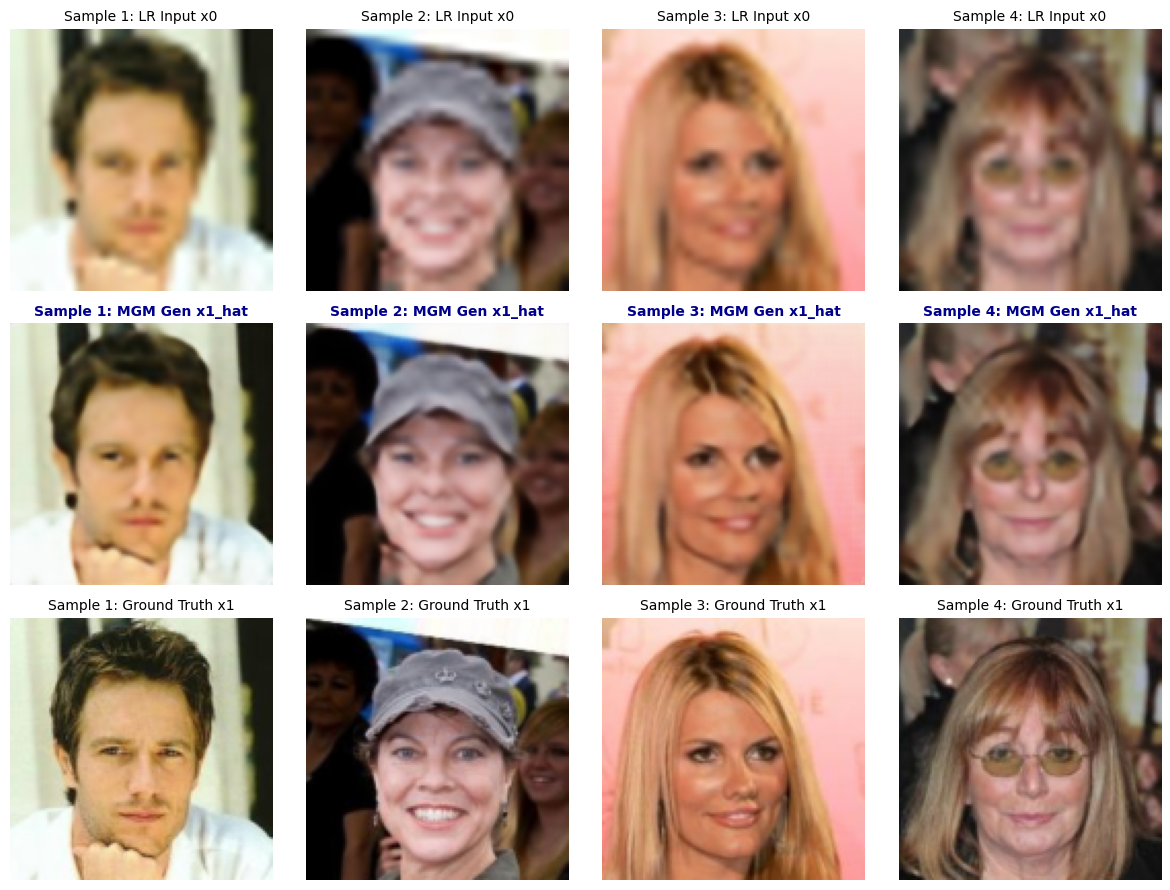

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

test_dataloader = get_celeba_dataloader(batch_size=4, num_samples=10000)
evaluate_and_plot_mgm(trained_generator, test_dataloader, device=device)

#### 1.4) Save checkpoint

In [ ]:
def save_mgm_checkpoint(
    generator,
    critic=None,
    opt_g=None,
    opt_c=None,
    epoch=5,
    descriptor="exp1_5ep_32to128",
    save_dir="./checkpoints"
):
    os.makedirs(save_dir, exist_ok=True)
    checkpoint_path = os.path.join(save_dir, f"mgm_{descriptor}.pt")

    # Construct checkpoint dictionary
    checkpoint = {
        "descriptor": descriptor,
        "epoch": epoch,
        "generator_state_dict": generator.state_dict(),
    }

    # Optionally include critic and optimizer states if provided
    if critic is not None:
        checkpoint["critic_state_dict"] = critic.state_dict()
    if opt_g is not None:
        checkpoint["opt_g_state_dict"] = opt_g.state_dict()
    if opt_c is not None:
        checkpoint["opt_c_state_dict"] = opt_c.state_dict()

    # Save to disk
    torch.save(checkpoint, checkpoint_path)
    print(f"Checkpoint successfully saved to: {checkpoint_path}")

    return checkpoint_path

In [ ]:
saved_path = save_mgm_checkpoint(
    generator=trained_generator,
    descriptor="exp1_5ep_celeba10k_32t128",
    save_dir=CHECKPOINTS_PATH
)

NameError: name 'trained_generator' is not defined

#### 1.5) Loading saved model

In [ ]:
generator = CelebAUNetGenerator().to(device)

# checkpoint = torch.load(CHECKPOINTS_PATH + '/' + "mgm_exp1_5ep_celeba10k_32t128", map_location=device)

checkpoint = torch.load("/content/drive/MyDrive/Skoltech/MGM/checkpoints/mgm_exp1_5ep_celeba10k_32t128.pt", map_location=device)
generator.load_state_dict(checkpoint["generator_state_dict"])
generator.eval()

print(f"Loaded MGM Generator weights from '{checkpoint['descriptor']}' (Epoch {checkpoint['epoch']})")

Loaded MGM Generator weights from 'exp1_5ep_celeba10k_32t128' (Epoch 5)


In [ ]:
/content/drive/MyDrive/Skoltech/MGM/checkpoints/mgm_exp1_5ep_celeba10k_32t128.pt

## 2) Updated training dynamics -> corrected version

#### 2.0) Meters and utilities

In [6]:
class TimeMeter:
    def __init__(self, device):
        self.device = torch.device(device)
        self.wall_start = time.perf_counter()
        self.gpu_seconds = 0.0
        self.start_event = None
        self.end_event = None

        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)
            self.start_event = torch.cuda.Event(enable_timing=True)
            self.end_event = torch.cuda.Event(enable_timing=True)
            self.start_event.record()

    def finish(self):
        wall_seconds = time.perf_counter() - self.wall_start

        if self.device.type == "cuda":
            self.end_event.record()
            torch.cuda.synchronize(self.device)
            self.gpu_seconds = self.start_event.elapsed_time(
                self.end_event
            ) / 1000.0

        return {
            "wall_hours": wall_seconds / 3600,
            "gpu_hours": self.gpu_seconds / 3600,
            "gpu_seconds": self.gpu_seconds,
        }

#### 2.1) Models + losses

In [7]:
from unet_modules import (
    make_group_norm,
    TimeEmbedding,
    ResidualBlock,
    Downsample,
    Upsample
)

In [8]:
class CelebACriticField(nn.Module):
    """
    Source-conditioned MGM displacement field.

    Inputs:
        t:       [N] or [N, 1, 1, 1]
        x_tilde: [N, C, H, W]
        x_0:     [N, C, H, W]

    Output:
        drift:   [N, C, H, W]
    """

    def __init__(
        self,
        in_channels=3,
        out_channels=3,
        base_channels=32,
        time_embedding_dim=64,
    ):
        super().__init__()

        c = base_channels
        time_channels = 4 * c

        self.time_mlp = nn.Sequential(
            TimeEmbedding(time_embedding_dim),
            nn.Linear(time_embedding_dim, time_channels),
            nn.SiLU(),
            nn.Linear(time_channels, time_channels),
        )

        self.init_conv = nn.Conv2d(
            2 * in_channels, c, 3, padding=1
        )

        self.enc1 = ResidualBlock(
            c, c, time_channels
        )
        self.down1 = Downsample(c)

        self.enc2 = ResidualBlock(
            c, 2 * c, time_channels
        )
        self.down2 = Downsample(2 * c)

        self.bottleneck1 = ResidualBlock(
            2 * c, 4 * c, time_channels
        )
        self.bottleneck2 = ResidualBlock(
            4 * c, 4 * c, time_channels
        )

        self.up2 = Upsample(4 * c)
        self.dec2 = ResidualBlock(
            6 * c, 2 * c, time_channels
        )

        self.up1 = Upsample(2 * c)
        self.dec1 = ResidualBlock(
            3 * c, c, time_channels
        )

        self.out_norm = make_group_norm(c)
        self.final_conv = nn.Conv2d(
            c, out_channels, 3, padding=1
        )

        # Small, nonzero initialization:
        # start near zero while retaining input/time dependence.
        nn.init.normal_(
            self.final_conv.weight, mean=0.0, std=1e-3
        )
        nn.init.zeros_(self.final_conv.bias)

    def forward(self, t, x_tilde, x_0):
        if x_tilde.shape != x_0.shape:
            raise ValueError(
                "x_tilde and x_0 must have the same shape."
            )

        N = x_tilde.shape[0]
        t = t.reshape(-1)

        if t.numel() != N:
            raise ValueError(
                "Provide one timestep per batch element."
            )

        t_emb = self.time_mlp(
            t.to(device=x_tilde.device)
        )

        h = self.init_conv(
            torch.cat([x_tilde, x_0], dim=1)
        )

        e1 = self.enc1(h, t_emb)
        e2 = self.enc2(self.down1(e1), t_emb)

        h = self.bottleneck1(
            self.down2(e2), t_emb
        )
        h = self.bottleneck2(h, t_emb)

        h = self.up2(h, e2.shape[-2:])
        h = self.dec2(
            torch.cat([h, e2], dim=1), t_emb
        )

        h = self.up1(h, e1.shape[-2:])
        h = self.dec1(
            torch.cat([h, e1], dim=1), t_emb
        )

        return self.final_conv(
            F.silu(self.out_norm(h))
        )

In [9]:
class CelebAUNetGenerator(nn.Module):
    """
    Deterministic paired image-to-image generator.

    Input:
        x_0: [N, C, H, W], LR image already upsampled
             to the target resolution.

    Output:
        x_0_hat: [N, C, H, W]

    Starts as the identity mapping.
    """

    def __init__(
        self,
        in_channels=3,
        out_channels=3,
        base_channels=32,
    ):
        super().__init__()

        if in_channels != out_channels:
            raise ValueError(
                "The image residual skip requires "
                "in_channels == out_channels."
            )

        c = base_channels

        self.init_conv = nn.Conv2d(
            in_channels, c, 3, padding=1
        )

        self.enc1 = ResidualBlock(c, c)
        self.down1 = Downsample(c)

        self.enc2 = ResidualBlock(c, 2 * c)
        self.down2 = Downsample(2 * c)

        self.bottleneck = nn.Sequential(
            ResidualBlock(2 * c, 4 * c),
            ResidualBlock(4 * c, 4 * c),
        )

        self.up2 = Upsample(4 * c)
        self.dec2 = ResidualBlock(6 * c, 2 * c)

        self.up1 = Upsample(2 * c)
        self.dec1 = ResidualBlock(3 * c, c)

        self.out_norm = make_group_norm(c)
        self.out = nn.Conv2d(
            c, out_channels, 3, padding=1
        )

        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)


    def forward(self, x_0):
        h = self.init_conv(x_0)

        e1 = self.enc1(h)
        e2 = self.enc2(self.down1(e1))

        h = self.bottleneck(self.down2(e2))

        h = self.up2(h, e2.shape[-2:])
        h = self.dec2(torch.cat([h, e2], dim=1))

        h = self.up1(h, e1.shape[-2:])
        h = self.dec1(torch.cat([h, e1], dim=1))

        residual = self.out(
            F.silu(self.out_norm(h))
        )

        return x_0 + residual

In [10]:
# =====================================================================
# FIELD DIVERGENCE LOSS -> f
# =====================================================================
def mgm_loss_f(G, f, x_0, x_1, eps=0.01):
    N = x_0.shape[0]
    device = x_0.device

    with torch.no_grad():
        x_0_hat = G(x_0)

    if x_0_hat.shape != x_1.shape:
        raise ValueError(
            f"G(x_0) shape {x_0_hat.shape} must match "
            f"x_1 shape {x_1.shape}."
        )

    t = torch.rand(N, 1, 1, 1, device=device) * 0.5
    noise = torch.randn_like(x_0_hat)
    b = (
        torch.rand(N, 1, 1, 1, device=device) < 0.5
    ).float()

    x_t = x_0_hat * (1.0 - t) + x_1 * t
    x_1mt = x_0_hat * t + x_1 * (1.0 - t)

    sigma_t = torch.sqrt(eps * t * (1.0 - t))

    x_tilde = (
        (1.0 - b) * (x_t + noise * sigma_t)
        + b * (x_1mt + noise * sigma_t)
    )

    target = (x_1 - x_0_hat).detach()
    pred = f(t.view(N), x_tilde, x_0)

    if pred.shape != target.shape:
        raise ValueError("Field output must match displacement shape.")

    # Mean over coordinates, then mean over examples.
    L_f = (
        (pred.float() - target.float())
        .square()
        .flatten(1)
        .mean(1)
        .mean()
    )

    return L_f


# =====================================================================
# Generator loss -> G
# =====================================================================
def mgm_loss_G(G, f, x_0, x_1, eps=0.01):
    N = x_0.shape[0]
    device = x_0.device

    x_0_hat = G(x_0)

    if x_0_hat.shape != x_1.shape:
        raise ValueError(
            f"G(x_0) shape {x_0_hat.shape} must match "
            f"x_1 shape {x_1.shape}."
        )

    t = torch.rand(N, 1, 1, 1, device=device) * 0.5
    noise = torch.randn_like(x_0_hat)
    b = (
        torch.rand(N, 1, 1, 1, device=device) < 0.5
    ).float()

    x_t = x_0_hat * (1.0 - t) + x_1 * t
    x_1mt = x_0_hat * t + x_1 * (1.0 - t)

    sigma_t = torch.sqrt(eps * t * (1.0 - t))

    x_tilde = (
        (1.0 - b) * (x_t + noise * sigma_t)
        + b * (x_1mt + noise * sigma_t)
    )

    # Do not detach either path during the generator update.
    drift = f(t.view(N), x_tilde, x_0)
    target = x_1 - x_0_hat

    if drift.shape != target.shape:
        raise ValueError("Field output must match displacement shape.")

    drift = drift.float()
    target = target.float()

    # Positive sign: generator minimizes the variational objective.
    L_G = (
        drift * (2.0 * target - drift)
    ).flatten(1).mean(1).mean()

    return L_G, x_0_hat

In [11]:
# =====================================================================
# HOLD_OUT VALIDATION
# =====================================================================
@torch.no_grad()
def validate_mgm_celeba(generator, val_dataloader, device):
    was_training = generator.training
    generator.eval()

    total_l1 = 0.0
    total_mse = 0.0
    total_outside = 0.0
    total_pixels = 0

    try:
        for x_0, x_1 in val_dataloader:
            x_0 = x_0.to(device, dtype=torch.float32)
            x_1 = x_1.to(device, dtype=torch.float32)

            x_0_hat = generator(x_0)

            if not torch.isfinite(x_0_hat).all():
                raise RuntimeError("Non-finite validation prediction.")

            error = x_0_hat.float() - x_1.float()

            total_l1 += error.abs().sum().item()
            total_mse += error.square().sum().item()

            # This diagnostic assumes images use the [0, 1] convention.
            total_outside += (
                (x_0_hat < 0.0) | (x_0_hat > 1.0)
            ).sum().item()
            total_pixels += x_1.numel()
    finally:
        generator.train(was_training)

    if total_pixels == 0:
        raise ValueError("Validation dataloader is empty.")

    return {
        "val_l1": total_l1 / total_pixels,
        "val_mse": total_mse / total_pixels,
        "val_outside_fraction": total_outside / total_pixels,
    }

In [12]:
# =====================================================================
# TRAINING FUNCTION
# =====================================================================
def train_mgm(
    generator,
    field,
    dataloader,
    epochs=10,
    lr_g=1e-5,
    lr_f=1e-5,
    lambda_l1=0.0,
    eps=0.01,
    device="cuda",
    max_grad_norm=1.0,
    ema_decay=0.999,
    val_dataloader=None,
    checkpoint=None
):
    if eps < 0:
        raise ValueError("eps must be nonnegative.")
    if lambda_l1 < 0:
        raise ValueError("lambda_l1 must be nonnegative.")
    if not 0.0 <= ema_decay < 1.0:
        raise ValueError("ema_decay must be in [0, 1).")
    if len(dataloader) < 2:
        raise ValueError(
            "Need at least two batches per epoch for fresh-batch "
            "field/generator alternation."
        )

    device = torch.device(device)

    # Start with float32 training for a clear correctness baseline.
    generator = generator.to(device=device, dtype=torch.float32)
    field = field.to(device=device, dtype=torch.float32)

    opt_g = torch.optim.Adam(
        generator.parameters(),
        lr=lr_g,
        betas=(0.0, 0.999),
    )
    opt_f = torch.optim.Adam(
        field.parameters(),
        lr=lr_f,
        betas=(0.0, 0.999),
    )

    generator_ema = copy.deepcopy(generator).eval()
    generator_ema.requires_grad_(False)

    history = []
    start_epoch = 0
    global_step = 0

    # Loading states from checpoint if provided
    if checkpoint is not None:
        print("Initialize training from the checkpoint:")
        generator.load_state_dict(checkpoint['generator_state_dict'])
        generator_ema.load_state_dict(checkpoint['generator_ema_state_dict'])
        field.load_state_dict(checkpoint['field_state_dict'])
        if "optimizer_g_state_dict" in checkpoint.keys():
            opt_g.load_state_dict(checkpoint["optimizer_g_state_dict"])
        if "optimizer_f_state_dict" in checkpoint.keys():
            opt_f.load_state_dict(checkpoint["optimizer_f_state_dict"])

        history = list(checkpoint.get("history", []))
        if history:
            start_epoch = history[-1]["epoch"]
            global_step = history[-1]["global_step"]
        else:
            start_epoch = checkpoint.get("epoch", 0)
            global_step = checkpoint.get("global_step", 0)

        print(
            f"Resuming after epoch {start_epoch}; "
            f"global_step={global_step}"
        )

    if lambda_l1 > 0:
        print("Objective: conditional MGM + L1 reconstruction")
    else:
        print("Objective: pure conditional MGM")

    print(
        f"Paired updates per epoch: {len(dataloader) // 2}; "
        "each paired update consumes two data batches."
    )

    for epoch_idx in range(epochs):
        epoch = start_epoch + epoch_idx + 1
        generator.train()
        field.train()

        sum_loss_f = 0.0
        sum_loss_mgm = 0.0
        sum_loss_l1 = 0.0
        sum_loss_g = 0.0
        n_updates = 0

        # Ordinary finite iteration over this epoch.
        batch_iterator = iter(dataloader)

        for batch_idx in range(len(dataloader) // 2):
            # ---------------------------------------------------------
            # Step 1: field update on the first batch
            # ---------------------------------------------------------
            x_0, x_1 = next(batch_iterator)
            x_0 = x_0.to(device, dtype=torch.float32)
            x_1 = x_1.to(device, dtype=torch.float32)

            field.requires_grad_(True)
            opt_f.zero_grad(set_to_none=True)

            loss_f = mgm_loss_f(
                generator, field, x_0, x_1, eps=eps
            )

            if not torch.isfinite(loss_f):
                raise RuntimeError("Non-finite field loss.")

            loss_f.backward()

            if max_grad_norm is not None:
                grad_norm_f = torch.nn.utils.clip_grad_norm_(
                    field.parameters(),
                    max_norm=max_grad_norm,
                    error_if_nonfinite=True,
                )
                grad_norm_f = grad_norm_f.item()
            else:
                grad_norm_f = float("nan")

            opt_f.step()
            opt_f.zero_grad(set_to_none=True)

            # ---------------------------------------------------------
            # Step 2: generator update on a fresh data batch
            # ---------------------------------------------------------
            x_0, x_1 = next(batch_iterator)
            x_0 = x_0.to(device, dtype=torch.float32)
            x_1 = x_1.to(device, dtype=torch.float32)

            field.requires_grad_(False)
            opt_g.zero_grad(set_to_none=True)

            try:
                loss_mgm, x_0_hat = mgm_loss_G(
                    generator, field, x_0, x_1, eps=eps
                )

                if lambda_l1 > 0:
                    loss_l1 = F.l1_loss(x_0_hat, x_1)
                    loss_g = loss_mgm + lambda_l1 * loss_l1
                else:
                    # Diagnostic only; no L1 term enters optimization.
                    with torch.no_grad():
                        loss_l1 = F.l1_loss(x_0_hat, x_1)
                    loss_g = loss_mgm

                if not torch.isfinite(loss_g):
                    raise RuntimeError("Non-finite generator loss.")

                loss_g.backward()

                if max_grad_norm is not None:
                    grad_norm_g = torch.nn.utils.clip_grad_norm_(
                        generator.parameters(),
                        max_norm=max_grad_norm,
                        error_if_nonfinite=True,
                    )
                    grad_norm_g = grad_norm_g.item()
                else:
                    grad_norm_g = float("nan")

                opt_g.step()

            finally:
                # Restore the field even if the generator step fails.
                field.requires_grad_(True)

            # ---------------------------------------------------------
            # Generator EMA
            # ---------------------------------------------------------
            with torch.no_grad():
                for p_ema, p in zip(
                    generator_ema.parameters(),
                    generator.parameters(),
                ):
                    p_ema.mul_(ema_decay).add_(
                        p, alpha=1.0 - ema_decay
                    )

                for b_ema, b in zip(
                    generator_ema.buffers(),
                    generator.buffers(),
                ):
                    b_ema.copy_(b)

            global_step += 1
            n_updates += 1

            sum_loss_f += loss_f.item()
            sum_loss_mgm += loss_mgm.item()
            sum_loss_l1 += loss_l1.item()
            sum_loss_g += loss_g.item()

            if batch_idx % 50 == 0:
                print(
                    f"Epoch [{epoch}/{start_epoch + epochs}] "
                    f"Update [{batch_idx + 1}/"
                    f"{len(dataloader) // 2}] | "
                    f"F: {loss_f.item():.6f} | "
                    f"MGM: {loss_mgm.item():.6f} | "
                    f"L1 diagnostic: {loss_l1.item():.6f} | "
                    f"Grad F: {grad_norm_f:.4f} | "
                    f"Grad G: {grad_norm_g:.4f}"
                )

            # Avoid retaining the generator graph between updates.
            del x_0_hat, loss_f, loss_mgm, loss_l1, loss_g

        row = {
            "epoch": epoch,
            "global_step": global_step,
            "loss_f": sum_loss_f / n_updates,
            "loss_mgm": sum_loss_mgm / n_updates,
            "loss_l1": sum_loss_l1 / n_updates,
            "loss_g": sum_loss_g / n_updates,
        }

        if val_dataloader is not None:
            row.update(
                validate_mgm_celeba(
                    generator_ema, val_dataloader, device
                )
            )
            print(
                f"EMA validation | "
                f"L1: {row['val_l1']:.6f} | "
                f"MSE: {row['val_mse']:.6f} | "
                f"Outside [0,1]: "
                f"{100 * row['val_outside_fraction']:.2f}%"
            )

        history.append(row)

    return generator, generator_ema, opt_g, opt_f, history

In [ ]:
# checkpoint saver
def save_mgm_checkpoint(
    path,
    generator,
    generator_ema,
    field,
    history,
    config=None,
    optimizer_g=None,
    optimizer_f=None,
    epoch=None,
):

    checkpoint = {
        "generator_state_dict": generator.state_dict(),
        "generator_ema_state_dict": generator_ema.state_dict(),
        "field_state_dict": field.state_dict(),
        "history": history,
        "config": config or {},
        "epoch": epoch
    }

    if optimizer_g is not None:
        checkpoint["optimizer_g_state_dict"] = optimizer_g.state_dict()

    if optimizer_f is not None:
        checkpoint["optimizer_f_state_dict"] = optimizer_f.state_dict()

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    torch.save(checkpoint, path)
    print(f"Checkpoint saved to: {path.resolve()}")

#### 2.2) MNIST training

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

generator = CelebAUNetGenerator(
    in_channels=1,
    out_channels=1,
    base_channels=32,
).to(device)

field = CelebACriticField(
    in_channels=1,
    out_channels=1,
    base_channels=32,
    time_embedding_dim=64,
).to(device)

print("Generator parameters:", f"{sum(p.numel() for p in generator.parameters()):,}")
print("Field parameters:", f"{sum(p.numel() for p in field.parameters()):,}")

Using device: cuda
Generator parameters: 1,034,273
Field parameters: 1,174,977


In [ ]:
# HERE I RESUME TRAINING FROM 20 TO 30 EPOCHS
checkp = torch.load(
    CHECKPOINTS_PATH + "/" + "mgm_exp6_20ep_mnist_10t64.pt",
    map_location=device,
    weights_only=False,
)

In [ ]:
# look at validation metrics for identity mapping
@torch.no_grad()
def evaluate_identity(dataloader):
    total_abs = 0.0
    total_sq = 0.0
    total_pixels = 0

    for x_0, x_1 in dataloader:
        error = x_0.to(device) - x_1.to(device)

        total_abs += error.abs().sum().item()
        total_sq += error.square().sum().item()
        total_pixels += x_1.numel()

    return {
        "l1": total_abs / total_pixels,
        "mse": total_sq / total_pixels,
    }

print(evaluate_identity(mnist_val_loader))

{'l1': 0.0685149778842926, 'mse': 0.017976186728477478}


In [ ]:
# training
meter = TimeMeter(device)

generator, generator_ema, opt_g, opt_f, history = train_mgm(
    generator=generator,
    field=field,
    dataloader=mnist_train_loader,
    val_dataloader=mnist_val_loader,
    epochs=10,    # additional 10 epochs from 21 to 30 now
    lr_g=1e-5,
    lr_f=1e-5,
    lambda_l1=0.0,
    eps=0.01,
    max_grad_norm=1.0,
    ema_decay=0.999,
    device=device,
    checkpoint=checkp
)

cost = meter.finish()
print(f"\nGPU-hours: {cost['gpu_hours']:.4f}")
print(f"GPU execution seconds: {cost['gpu_seconds']:.1f}")
print(f"Wall-clock hours: {cost['wall_hours']:.4f}")

Initialize training from the checkpoint:
Resuming after epoch 20; global_step=9360
Objective: pure conditional MGM
Paired updates per epoch: 468; each paired update consumes two data batches.
Epoch [21/30] Update [1/468] | F: 0.002797 | MGM: 0.000191 | L1 diagnostic: 0.022524 | Grad F: 0.0358 | Grad G: 0.0220
Epoch [21/30] Update [51/468] | F: 0.002848 | MGM: 0.000190 | L1 diagnostic: 0.022415 | Grad F: 0.0488 | Grad G: 0.0212
Epoch [21/30] Update [101/468] | F: 0.002379 | MGM: 0.000106 | L1 diagnostic: 0.022123 | Grad F: 0.0484 | Grad G: 0.0217
Epoch [21/30] Update [151/468] | F: 0.002601 | MGM: 0.000138 | L1 diagnostic: 0.022698 | Grad F: 0.0535 | Grad G: 0.0313
Epoch [21/30] Update [201/468] | F: 0.002562 | MGM: 0.000178 | L1 diagnostic: 0.023986 | Grad F: 0.0365 | Grad G: 0.0226
Epoch [21/30] Update [251/468] | F: 0.002632 | MGM: 0.000132 | L1 diagnostic: 0.022820 | Grad F: 0.0229 | Grad G: 0.0153
Epoch [21/30] Update [301/468] | F: 0.002600 | MGM: 0.000127 | L1 diagnostic: 0.02236

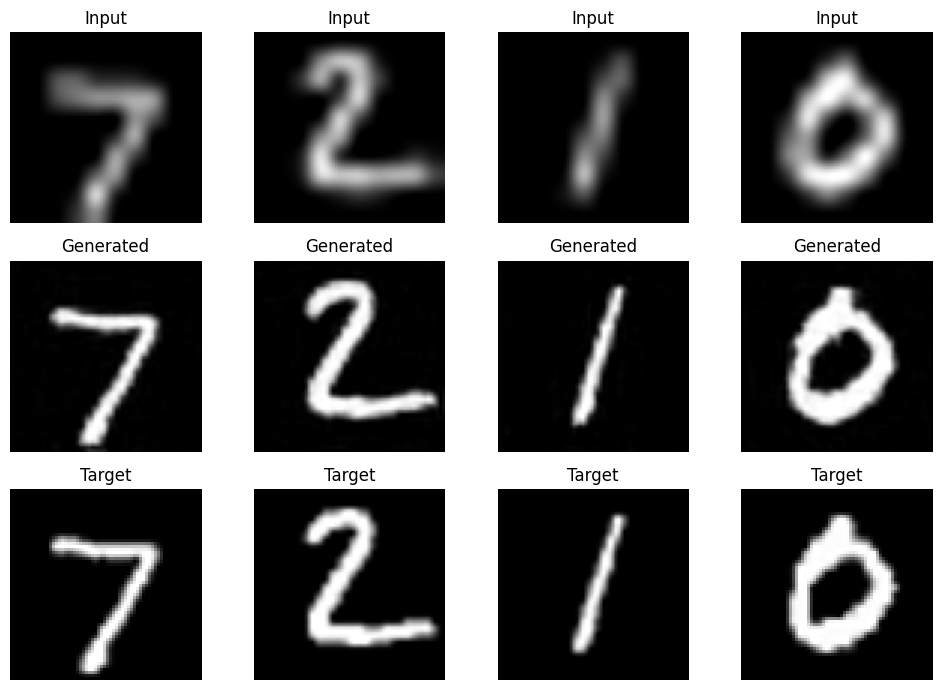

In [ ]:
# generate + visualize samples
generator_ema.eval()

x0_batch, x1_batch = next(iter(mnist_val_loader))
x0_batch = x0_batch.to(device)
x1_batch = x1_batch.to(device)

with torch.no_grad():
    x_pred = generator_ema(x0_batch)

fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for i in range(4):
    axes[0, i].imshow(x0_batch[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title("Input")
    axes[1, i].imshow(x_pred[i, 0].cpu().clamp(0, 1), cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Generated")
    axes[2, i].imshow(x1_batch[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].set_title("Target")

    for row in range(3):
        axes[row, i].axis("off")

plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
from torchmetrics.image import (
    StructuralSimilarityIndexMeasure,
    PeakSignalNoiseRatio,
)

def evaluate_method(model, val_loader, device, identity=False):
    ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)

    abs_error_sum = 0.0
    sq_error_sum = 0.0
    num_pixels = 0

    if model is not None:
        model.eval()

    val_timer = TimeMeter(device)

    with torch.no_grad():
        for x0, x1 in val_loader:
            x0 = x0.to(device)
            x1 = x1.to(device)

            if identity:
                pred = x0
            else:
                pred = model(x0).clamp(0, 1)

            abs_error_sum += (pred - x1).abs().sum().item()
            sq_error_sum += ((pred - x1) ** 2).sum().item()
            num_pixels += x1.numel()

            ssim.update(pred, x1)
            psnr.update(pred, x1)

    val_time = val_timer.finish()
    # print(f"Validation GPU-hours: {val_time['gpu_hours']:.4f}")
    # print(f"Validation wall-hours: {val_time['wall_hours']:.4f}")
    mse = sq_error_sum / num_pixels

    results = {
        "MAE": abs_error_sum / num_pixels,
        "MSE": mse,
        "PSNR (dB)": psnr.compute().item(),
        "SSIM": ssim.compute().item(),
    }

    ssim.reset()
    psnr.reset()

    return results, val_time

In [ ]:
results = {
    "Identity (bicubic input)": evaluate_method(
        None, mnist_val_loader, device, identity=True
    )[0],
    "Generator": evaluate_method(
        generator, mnist_val_loader, device
    )[0],
    "EMA Generator": evaluate_method(
        generator_ema, mnist_val_loader, device
    )[0],
}

df = pd.DataFrame(results).T
df.round(5)

,MAE,MSE,PSNR (dB),SSIM
Identity (bicubic input),0.06851,0.01798,17.45303,0.68685
Generator,0.01771,0.00234,26.30588,0.90804
EMA Generator,0.01724,0.00221,26.54635,0.91146


In [ ]:
# save this checkpoint
checkpoint_path = CHECKPOINTS_PATH + '/' + "mgm_exp7_30ep_mnist_10t64.pt"

config = {
    "dataset": "MNIST",
    "source_resolution": 10,
    "target_resolution": 64,
    "channels": 1,
    "epochs": 30,
    "lr_g": 1e-5,
    "lr_f": 1e-5,
    "lambda_l1": 0.0,
    "eps": 0.01,
    "ema_decay": 0.999,
}

save_mgm_checkpoint(
    path=checkpoint_path,
    generator=generator,
    generator_ema=generator_ema,
    field=field,
    optimizer_g=opt_g,
    optimizer_f=opt_f,
    history=history,
    config=config
)

Checkpoint saved to: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/mgm_exp7_30ep_mnist_10t64.pt


#### 3) Baselines -> L1/L2 regression

In [ ]:
import os
import sys

print("Working directory:", os.getcwd())
print("Files here:", os.listdir())
print("Python search paths:", sys.path[:5])

Working directory: /content
Files here: ['.config', 'data', 'drive', 'sample_data']
Python search paths: ['/content/drive/MyDrive/AI_Notebooks/MGM', '/content', '/env/python', '/usr/lib/python313.zip', '/usr/lib/python3.13']


In [12]:
from training import (
    train_pbp_regression,
    train_cfm,
    update_ema,
    save_checkpoint_atomic,
    load_checkpoint
)

from validation import (
    validate_super_resolution,
    evaluate_method,
    sample_cfm_ode
)

In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# generator = CelebAUNetGenerator(
#     in_channels=1,
#     out_channels=1,
#     base_channels=32,
# ).to(device)

field = CelebACriticField(
    in_channels=1,
    out_channels=1,
    base_channels=32,
    time_embedding_dim=64,
).to(device)

Using device: cuda


In [ ]:
import inspect
import training

print("Imported from:", training.__file__)
print(inspect.signature(training.train_pbp_regression))

Imported from: /content/drive/MyDrive/AI_Notebooks/MGM/training.py
(generator, dataloader, epochs=10, pixel_loss='l1', lr=1e-05, device='cuda', max_grad_norm=1.0, ema_decay=0.999, val_dataloader=None, checkpoint=None, checkpoint_path=None, checkpoint_every=1, log_every=50, restore_rng=True)


In [14]:
# generator, generator_ema, history, state = train_pbp_regression(
#     generator=generator,
#     dataloader=mnist_train_loader,
#     val_dataloader=mnist_val_loader,
#     epochs=10,
#     pixel_loss="l1",
#     lr=1e-5,
#     device=device,
#     checkpoint=(CHECKPOINTS_PATH + '/' + "l1_exp8_20ep_mnist_10t64.pt"),
#     checkpoint_path=(CHECKPOINTS_PATH + '/' + "pbp_l1_trial2.pt"),
#     checkpoint_every=5,
#     log_every=None,  # Automatically aims for ~10 logs per epoch
# )

field_cfm, field_cfm_ema, cfm_history, cfm_state = train_cfm(
    field=field,
    dataloader=mnist_train_loader,
    val_dataloader=mnist_val_loader,
    epochs=30,
    lr=1e-5,
    device=device,
    ema_decay=0.999,
    validation_steps=20,
    ode_solver="euler",
    checkpoint_path=CHECKPOINTS_PATH + "/mnist_cfm.pt",
    checkpoint_every=5,
    validate_every=5
)


Starting CFM epoch [1/30]; ODE validation steps=20; logging every 94 batches
CFM | Epoch [1/30] Batch [1/937] | Loss: 0.018346 | Endpoint-proxy MAE: 0.072240 | Grad: 0.4231
CFM | Epoch [1/30] Batch [94/937] | Loss: 0.004692 | Endpoint-proxy MAE: 0.034370 | Grad: 0.2863
CFM | Epoch [1/30] Batch [188/937] | Loss: 0.002076 | Endpoint-proxy MAE: 0.022802 | Grad: 0.0744
CFM | Epoch [1/30] Batch [282/937] | Loss: 0.001420 | Endpoint-proxy MAE: 0.019343 | Grad: 0.0708
CFM | Epoch [1/30] Batch [376/937] | Loss: 0.001301 | Endpoint-proxy MAE: 0.018153 | Grad: 0.0820
CFM | Epoch [1/30] Batch [470/937] | Loss: 0.001021 | Endpoint-proxy MAE: 0.016309 | Grad: 0.0484
CFM | Epoch [1/30] Batch [564/937] | Loss: 0.000857 | Endpoint-proxy MAE: 0.015236 | Grad: 0.0634
CFM | Epoch [1/30] Batch [658/937] | Loss: 0.000901 | Endpoint-proxy MAE: 0.015214 | Grad: 0.0351
CFM | Epoch [1/30] Batch [752/937] | Loss: 0.000699 | Endpoint-proxy MAE: 0.013495 | Grad: 0.0660
CFM | Epoch [1/30] Batch [846/937] | Loss: 

In [ ]:
from validation import sample_cfm_ode

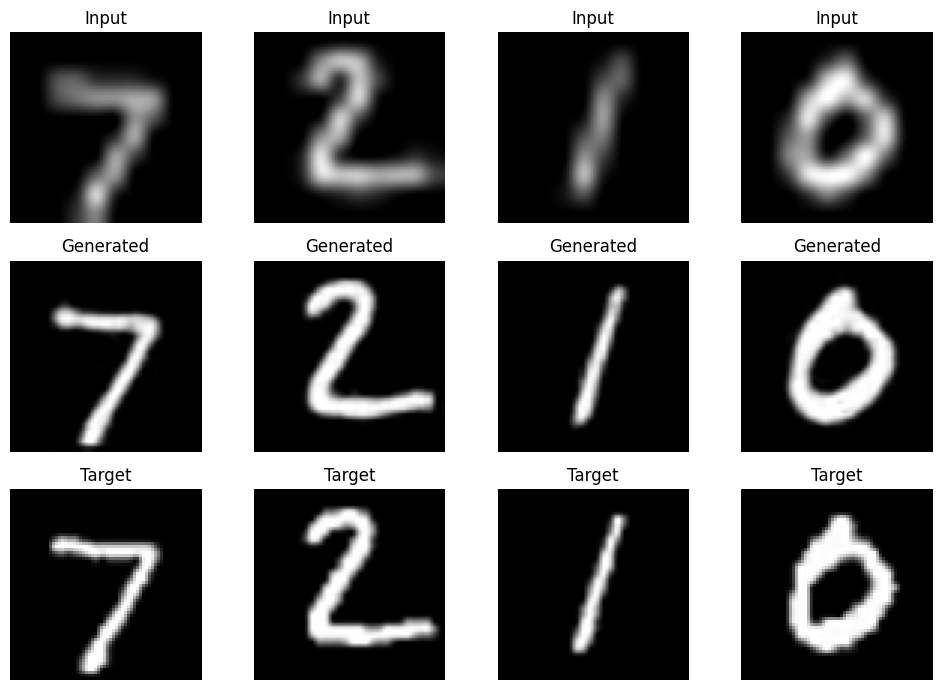

In [19]:
# generate + visualize samples
field_cfm_ema.eval()

x0_batch, x1_batch = next(iter(mnist_val_loader))
x0_batch = x0_batch.to(device)
x1_batch = x1_batch.to(device)

with torch.no_grad():
    x_pred = sample_cfm_ode(field_cfm_ema, x0_batch, n_steps=20)

fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for i in range(4):
    axes[0, i].imshow(x0_batch[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title("Input")
    axes[1, i].imshow(x_pred[i, 0].cpu().clamp(0, 1), cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Generated")
    axes[2, i].imshow(x1_batch[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].set_title("Target")

    for row in range(3):
        axes[row, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
results = {
    "Identity (bicubic input)": evaluate_method(
        None, mnist_val_loader, device, identity=True
    )[0],
    "Generator": evaluate_method(
        generator, mnist_val_loader, device
    )[0],
    "EMA Generator": evaluate_method(
        generator_ema, mnist_val_loader, device
    )[0],
}

df = pd.DataFrame(results).T
df.round(5)

,MAE,MSE,PSNR (dB),SSIM
Identity (bicubic input),0.06851,0.01798,17.45303,0.68685
Generator,0.01112,0.00122,29.12168,0.98030
EMA Generator,0.01072,0.00123,29.10613,0.98205


In [22]:
# Effect of ODE sampling steps for CFM
results = {
    f"CFM ({steps} steps)": evaluate_method(
        field_cfm_ema,
        mnist_val_loader,
        device,
        method="cfm",
        ode_steps=steps,
        ode_solver="euler",
        clamp=True,
    )[0]
    for steps in [1, 5, 10, 20, 50]
}

df = pd.DataFrame(results).T
df.round(5)

,MAE,MSE,PSNR (dB),SSIM
CFM (1 steps),0.01999,0.00295,25.29548,0.92003
CFM (5 steps),0.01820,0.00280,25.52144,0.94881
CFM (10 steps),0.01780,0.00277,25.57644,0.95396
CFM (20 steps),0.01749,0.00273,25.63775,0.95637
CFM (50 steps),0.01719,0.00268,25.72573,0.95746


### 4) Profiling -> Calculating FLOPs for each method

##### 4.1) Profile inference FLOPs

In [23]:
!pip install fvcore -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 9.4 MB/s eta 0:00:00


In [36]:
import gc
import time
import torch
import pandas as pd
import torch.nn as nn

from fvcore.nn import FlopCountAnalysis
from torch.profiler import profile, ProfilerActivity, record_function
from training import _restore_common, _make_optimizer, _clip_gradients, _batch_to_device

assert torch.cuda.is_available()
device = torch.device("cuda")

In [25]:
# Here we load models from corresponding checkpoints
mgm_generator = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)
mgm_field = CelebACriticField(in_channels=1, out_channels=1, base_channels=32, time_embedding_dim=64).to(device)
l1_generator = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)
cfm_field = CelebACriticField(in_channels=1, out_channels=1, base_channels=32, time_embedding_dim=64).to(device)

MODEL_OBJECTS = {
    "MGM": mgm_generator,
    "L1": l1_generator,
    "CFM": cfm_field,
}

# MGM's field is needed for its training profile, not normally for
# one-step generator inference.
MGM_FIELD = mgm_field

In [26]:
# Other constants

TRAIN_LOADER = mnist_train_loader
EPOCHS = 30
N_TRAIN = len(TRAIN_LOADER.dataset)
BATCH_SIZE_TRAIN = TRAIN_LOADER.batch_size
STEPS_PER_EPOCH = len(TRAIN_LOADER)
TOTAL_STEPS = EPOCHS * STEPS_PER_EPOCH

In [27]:
MEASURED_GPU_HOURS = {
    "MGM": None,
    "L1": None,
    "CFM": None,
}

print(f"Training examples: {N_TRAIN:,}")
print(f"Batch size: {BATCH_SIZE_TRAIN}")
print(f"Steps per epoch: {STEPS_PER_EPOCH:,}")
print(f"Total training iterations over {EPOCHS} epochs: {TOTAL_STEPS:,}")

Training examples: 60,000
Batch size: 64
Steps per epoch: 937
Total training iterations over 30 epochs: 28,110


In [28]:
class RegressionInference(nn.Module):
    """One-pass paired super-resolution inference."""
    def __init__(self, generator):
        super().__init__()
        self.generator = generator

    def forward(self, x_src):
        return self.generator(x_src)


class CFMInference(nn.Module):
    """One CFM velocity-field evaluation."""
    def __init__(self, field):
        super().__init__()
        self.field = field

    def forward(self, t, x_t, x_src):
        return self.field(t, x_t, x_src)


class MGMInference(nn.Module):
    def __init__(self, generator):
        super().__init__()
        self.generator = generator

    def forward(self, x_src):
        return self.generator(x_src)


inference_models = {
    "MGM": MGMInference(MODEL_OBJECTS["MGM"]),
    "L1": RegressionInference(MODEL_OBJECTS["L1"]),
    "CFM": CFMInference(MODEL_OBJECTS["CFM"]),
}

for model in inference_models.values():
    model.to(device).eval()

In [30]:
# MNIST is grayscale: [B, 1, H, W].
x_src_1 = torch.randn(1, 1, 10, 10, device=device)
x_hr_1  = torch.randn(1, 1, 64, 64, device=device)
t_1     = torch.zeros(1, device=device)

def count_fvcore_flops(model, inputs):
    model.eval()
    with torch.no_grad():
        analysis = FlopCountAnalysis(model, inputs)
        analysis.unsupported_ops_warnings(False)
        analysis.uncalled_modules_warnings(False)
        flops = analysis.total()

    return int(flops), analysis

inference_flops = {}

for name, model in inference_models.items():
    if name == "CFM":
        inputs = (t_1, torch.zeros_like(x_src_1), x_src_1)
    else:
        inputs = (x_src_1,)

    flops, analysis = count_fvcore_flops(model, inputs)
    inference_flops[name] = flops

    print(f"\n{name}: {flops:,} FLOPs per forward call")
    print(f"Unsupported operators: {analysis.unsupported_ops()}")


MGM: 24,160,928 FLOPs per forward call
Unsupported operators: Counter({'aten::silu': 13, 'aten::add': 7, 'aten::div': 6})

L1: 24,160,928 FLOPs per forward call
Unsupported operators: Counter({'aten::silu': 13, 'aten::add': 7, 'aten::div': 6})

CFM: 24,328,992 FLOPs per forward call
Unsupported operators: Counter({'aten::silu': 20, 'aten::add': 18, 'aten::mul': 8, 'aten::div': 6, 'aten::sin': 1, 'aten::cos': 1})


#### 4.2) Profile training iterations

In [45]:
def train_step_l1(generator, optimizer, generator_ema, batch, device):
    generator.train()

    x_src, x_hr = _batch_to_device(batch, device)
    optimizer.zero_grad(set_to_none=True)

    prediction = generator(x_src)
    loss = F.l1_loss(prediction, x_hr)

    loss.backward()
    _clip_gradients(generator, 1.0)
    optimizer.step()
    update_ema(generator_ema, generator, 0.999)

    return loss.detach()


def train_step_cfm( field, optimizer, field_ema, batch, device):
    field.train()

    x_src, x_hr = _batch_to_device(batch, device)
    optimizer.zero_grad(set_to_none=True)

    # Sample random times and construct the straight-line bridge
    batch_size = x_src.shape[0]
    t = torch.rand(batch_size, device=device)
    t_view = t.view(batch_size, *([1] * (x_src.ndim - 1)))

    x_t = (1.0 - t_view) * x_src + t_view * x_hr

    # Target velocity along the straight-line path
    target_velocity = x_hr - x_src

    # Predict the conditional velocity field
    predicted_velocity = field(t, x_t, x_src)
    loss = F.mse_loss(predicted_velocity, target_velocity)

    loss.backward()
    _clip_gradients(field, 1.0)
    optimizer.step()
    update_ema(field_ema, field, 0.999)

    return loss.detach()

In [33]:
def train_step_mgm(
    generator,
    field,
    opt_g,
    opt_f,
    generator_ema,
    batch_f,
    batch_g,
    device,
    eps=0.01,
    lambda_l1=0.0,
    max_grad_norm=1.0,
    ema_decay=0.999,
):
    generator.train()
    field.train()

    # =========================================================
    # Step 1: Update the field using its own batch
    # =========================================================
    x0_f, x1_f = _batch_to_device(batch_f, device)

    field.requires_grad_(True)
    opt_f.zero_grad(set_to_none=True)

    loss_f = mgm_loss_f(
        generator, field, x0_f, x1_f, eps=eps
    )

    if not torch.isfinite(loss_f):
        raise RuntimeError("Non-finite field loss.")

    loss_f.backward()

    if max_grad_norm is not None:
        torch.nn.utils.clip_grad_norm_(
            field.parameters(),
            max_norm=max_grad_norm,
            error_if_nonfinite=True,
        )

    opt_f.step()
    opt_f.zero_grad(set_to_none=True)

    # =========================================================
    # Step 2: Update the generator using a fresh batch
    # =========================================================
    x0_g, x1_g = _batch_to_device(batch_g, device)

    field.requires_grad_(False)
    opt_g.zero_grad(set_to_none=True)

    try:
        loss_mgm, x0_hat = mgm_loss_G(
            generator, field, x0_g, x1_g, eps=eps
        )

        if lambda_l1 > 0:
            loss_l1 = F.l1_loss(x0_hat, x1_g)
            loss_g = loss_mgm + lambda_l1 * loss_l1
        else:
            loss_g = loss_mgm

        if not torch.isfinite(loss_g):
            raise RuntimeError("Non-finite generator loss.")

        loss_g.backward()

        if max_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(
                generator.parameters(),
                max_norm=max_grad_norm,
                error_if_nonfinite=True,
            )

        opt_g.step()

    finally:
        field.requires_grad_(True)

    # =========================================================
    # Step 3: Update generator EMA
    # =========================================================
    with torch.no_grad():
        for p_ema, p in zip(
            generator_ema.parameters(),
            generator.parameters(),
        ):
            p_ema.mul_(ema_decay).add_(
                p, alpha=1.0 - ema_decay
            )

        for b_ema, b in zip(
            generator_ema.buffers(),
            generator.buffers(),
        ):
            b_ema.copy_(b)

    return {
        "loss_f": loss_f.detach(),
        "loss_mgm": loss_mgm.detach(),
        "loss_g": loss_g.detach(),
    }

In [49]:
# Profile MGM iteration
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(device)

mgm_generator = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)
mgm_generator_ema = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)
mgm_field = CelebACriticField(in_channels=1, out_channels=1, base_channels=32, time_embedding_dim=64).to(device)


# Create fresh optimizers matching train_mgm
opt_g = torch.optim.Adam(
    mgm_generator.parameters(), lr=1e-5, betas=(0.0, 0.999)
)
opt_f = torch.optim.Adam(
    mgm_field.parameters(), lr=1e-5, betas=(0.0, 0.999)
)

batch_iter = iter(mnist_train_loader)
batch_f = next(batch_iter)
batch_g = next(batch_iter)

# Warm up
for _ in range(3):
    train_step_mgm(
        mgm_generator, mgm_field, opt_g, opt_f, mgm_generator_ema,
        batch_f, batch_g, device,
        eps=0.01,
        lambda_l1=0.0,
        max_grad_norm=1.0,
        ema_decay=0.999,
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Profile one full field + generator update
activities = [torch.profiler.ProfilerActivity.CPU]
if torch.cuda.is_available():
    activities.append(torch.profiler.ProfilerActivity.CUDA)

with torch.profiler.profile(
    activities=activities,
    record_shapes=True,
    profile_memory=True,
    with_flops=True,
) as prof:
    train_step_mgm(
        mgm_generator, mgm_field, opt_g, opt_f, mgm_generator_ema,
        batch_f, batch_g, device,
        eps=0.01,
        lambda_l1=0.0,
        max_grad_norm=1.0,
        ema_decay=0.999,
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

# print(prof.key_averages().table(
#     sort_by="cuda_time_total" if torch.cuda.is_available()
#     else "cpu_time_total",
#     row_limit=20,
# ))

# Estimated FLOPs for one profiled training step
flops_per_step_mgm = sum(
    event.flops or 0
    for event in prof.key_averages()
)

# Peak GPU memory during profiling
if torch.cuda.is_available():
    peak_allocated_gb_mgm = (
        torch.cuda.max_memory_allocated(device) / 1024**3
    )
    peak_reserved_gb_mgm = (
        torch.cuda.max_memory_reserved(device) / 1024**3
    )
else:
    peak_allocated_gb_mgm = None
    peak_reserved_gb_mgm = None

print(f"Estimated FLOPs per step: {flops_per_step_mgm:.3e}")
print(f"Peak allocated VRAM: {peak_allocated_gb_mgm:.3f} GB"
      if peak_allocated_gb_mgm is not None else "CUDA unavailable")
print(f"Peak reserved VRAM: {peak_reserved_gb_mgm:.3f} GB"
      if peak_reserved_gb_mgm is not None else "CUDA unavailable")

Estimated FLOPs per step: 4.712e+11
Peak allocated VRAM: 2.713 GB
Peak reserved VRAM: 3.510 GB


In [50]:
# Profile L1-regressor iteration
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(device)

l1_generator = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)
l1_generator_ema = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)

# Create fresh optimizers matching train_pbp_regression
opt_g = torch.optim.Adam(
    l1_generator.parameters(), lr=1e-5, betas=(0.0, 0.999)
)

batch = next(iter(mnist_train_loader))

# Warm up
for _ in range(3):
    train_step_l1(
        l1_generator, opt_g, l1_generator_ema,
        batch, device
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Profile one full field + generator update
activities = [torch.profiler.ProfilerActivity.CPU]
if torch.cuda.is_available():
    activities.append(torch.profiler.ProfilerActivity.CUDA)

with torch.profiler.profile(
    activities=activities,
    record_shapes=True,
    profile_memory=True,
    with_flops=True,
) as prof:
    train_step_l1(
        l1_generator, opt_g, l1_generator_ema,
        batch, device
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

# print(prof.key_averages().table(
#     sort_by="cuda_time_total" if torch.cuda.is_available()
#     else "cpu_time_total",
#     row_limit=20,
# ))

# Estimated FLOPs for one profiled training step
flops_per_step_l1 = sum(
    event.flops or 0
    for event in prof.key_averages()
)

# Peak GPU memory during profiling
if torch.cuda.is_available():
    peak_allocated_gb_l1 = (
        torch.cuda.max_memory_allocated(device) / 1024**3
    )
    peak_reserved_gb_l1 = (
        torch.cuda.max_memory_reserved(device) / 1024**3
    )
else:
    peak_allocated_gb_l1 = None
    peak_reserved_gb_l1 = None

print(f"Estimated FLOPs per step: {flops_per_step_l1:.3e}")
print(f"Peak allocated VRAM: {peak_allocated_gb_l1:.3f} GB"
      if peak_allocated_gb_l1 is not None else "CUDA unavailable")
print(f"Peak reserved VRAM: {peak_reserved_gb_l1:.3f} GB"
      if peak_reserved_gb_l1 is not None else "CUDA unavailable")

Estimated FLOPs per step: 1.177e+11
Peak allocated VRAM: 1.571 GB
Peak reserved VRAM: 3.510 GB


In [51]:
# Profile CFM iteration
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(device)

cfm_field = CelebACriticField(in_channels=1, out_channels=1, base_channels=32, time_embedding_dim=64).to(device)
cfm_field_ema = CelebACriticField(in_channels=1, out_channels=1, base_channels=32, time_embedding_dim=64).to(device)

# Create fresh optimizers matching train_pbp_regression
opt_f = torch.optim.Adam(
    cfm_field.parameters(), lr=1e-5, betas=(0.0, 0.999)
)

batch = next(iter(mnist_train_loader))

# Warm up
for _ in range(3):
    train_step_cfm(cfm_field, opt_f, cfm_field_ema, batch, device)

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Profile one full field + generator update
activities = [torch.profiler.ProfilerActivity.CPU]
if torch.cuda.is_available():
    activities.append(torch.profiler.ProfilerActivity.CUDA)

with torch.profiler.profile(
    activities=activities,
    record_shapes=True,
    profile_memory=True,
    with_flops=True,
) as prof:
    train_step_cfm(cfm_field, opt_f, cfm_field_ema, batch, device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

# print(prof.key_averages().table(
#     sort_by="cuda_time_total" if torch.cuda.is_available()
#     else "cpu_time_total",
#     row_limit=20,
# ))

# Estimated FLOPs for one profiled training step
flops_per_step_cfm = sum(
    event.flops or 0
    for event in prof.key_averages()
)

# Peak GPU memory during profiling
if torch.cuda.is_available():
    peak_allocated_gb_cfm = (
        torch.cuda.max_memory_allocated(device) / 1024**3
    )
    peak_reserved_gb_cfm = (
        torch.cuda.max_memory_reserved(device) / 1024**3
    )
else:
    peak_allocated_gb_cfm = None
    peak_reserved_gb_cfm = None

print(f"Estimated FLOPs per step: {flops_per_step_cfm:.3e}")
print(f"Peak allocated VRAM: {peak_allocated_gb_cfm:.3f} GB"
      if peak_allocated_gb_cfm is not None else "CUDA unavailable")
print(f"Peak reserved VRAM: {peak_reserved_gb_cfm:.3f} GB"
      if peak_reserved_gb_cfm is not None else "CUDA unavailable")

Estimated FLOPs per step: 1.180e+11
Peak allocated VRAM: 1.654 GB
Peak reserved VRAM: 3.510 GB


In [52]:
epochs_trained = 30
iterations_per_epoch = len(mnist_train_loader)

total_iterations = epochs_trained * iterations_per_epoch
total_training_flops = [total_iterations * x for x in [flops_per_step_l1, flops_per_step_cfm, flops_per_step_mgm]]

images_processed = epochs_trained * len(mnist_train_loader.dataset)
training_flops_per_image = [(x / images_processed) for x in total_training_flops]

peak_allocated_vrams = [peak_allocated_gb_l1, peak_allocated_gb_cfm, peak_allocated_gb_mgm]
training_gpu_hours = [0.9124, 1.4249, 1.7959]

In [68]:
# corrections for MGM - [-1] element of lists
iterations_per_epoch_mgm = len(mnist_train_loader) // 2
total_iterations_mgm = epochs_trained * iterations_per_epoch_mgm
total_training_flops[-1] = (flops_per_step * total_iterations_mgm)

images_processed_mgm = (total_iterations_mgm * 2 * mnist_train_loader.batch_size)
training_flops_per_image[-1] = (total_training_flops[-1] / images_processed_mgm)

In [69]:
profiling_report = pd.DataFrame({
    "Method": ["L1", "CFM", "MGM"],
    "Total training compute (TFLOPs)": [
        flops / 1e12 for flops in total_training_flops
    ],
    "Training compute (GFLOPs/image)": [
        flops / 1e9 for flops in training_flops_per_image
    ],
    "Training GPU-hours": training_gpu_hours,
    "Peak allocated VRAM (GB)": peak_allocated_vrams,
})

profiling_report.round(3)

,Method,Total training compute (TFLOPs),Training compute (GFLOPs/image),Training GPU-hours,Peak allocated VRAM (GB)
0,L1,3307.163,1.837,0.912,1.571
1,CFM,3316.176,1.842,1.425,1.654
2,MGM,6615.302,3.681,1.796,2.713


### 5) Results -> Frechet Distance

In [13]:
import importlib

from validation import evaluate_method

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [13]:
# --------------------------------------------------
# 1. Set your checkpoint paths
# --------------------------------------------------
l1_checkpoint_path = CHECKPOINTS_PATH + "/pbp_l1_trial2.pt"
cfm_checkpoint_path = CHECKPOINTS_PATH + "/mnist_cfm.pt"
mgm_checkpoint_path = CHECKPOINTS_PATH + "/mgm_exp7_30ep_mnist_10t64.pt"

# --------------------------------------------------
# 2. Instantiate the same architectures used in training
#    Replace these constructors with your actual model classes.
# --------------------------------------------------
generator_l1 = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)
field_cfm = CelebACriticField(in_channels=1, out_channels=1, base_channels=32, time_embedding_dim=64).to(device)
generator_mgm = CelebAUNetGenerator(in_channels=1, out_channels=1, base_channels=32).to(device)



def load_checkpoint(path):
    return torch.load(path, map_location=device, weights_only=False)

def load_weights(model, checkpoint, candidate_keys):
    for key in candidate_keys:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            model.load_state_dict(checkpoint[key])
            return key

    # Also support a checkpoint that is itself a state dict.
    if all(isinstance(v, torch.Tensor) for v in checkpoint.values()):
        model.load_state_dict(checkpoint)
        return "raw state_dict"

    raise KeyError(
        f"Could not find model weights. Available keys: {list(checkpoint.keys())}"
    )

l1_ckpt = load_checkpoint(l1_checkpoint_path)
cfm_ckpt = load_checkpoint(cfm_checkpoint_path)
mgm_ckpt = load_checkpoint(mgm_checkpoint_path)

print("L1 weights:", load_weights(
    generator_l1, l1_ckpt,
    ["generator_ema_state_dict", "ema_state_dict", "model_state_dict",
     "generator_state_dict", "state_dict"]
))

print("CFM weights:", load_weights(
    field_cfm, cfm_ckpt,
    ["field_ema_state_dict", "ema_field_state_dict",
     "ema_state_dict", "field_state_dict", "model_state_dict", "state_dict"]
))

print("MGM weights:", load_weights(
    generator_mgm, mgm_ckpt,
    ["generator_ema_state_dict", "ema_state_dict",
     "generator_state_dict", "model_state_dict", "state_dict"]
))

L1 weights: generator_ema_state_dict
CFM weights: field_ema_state_dict
MGM weights: generator_ema_state_dict


In [ ]:
fd_samples = 100

results = {
    "Identity (bicubic input)": evaluate_method(
        None,
        mnist_val_loader,
        device,
        identity=True,
        fd_max_samples=fd_samples,
    )[0],

    "L1 EMA Generator": evaluate_method(
        generator_l1,
        mnist_val_loader,
        device,
        fd_max_samples=fd_samples,
    )[0],

    "CFM EMA Field": evaluate_method(
        field_cfm,
        mnist_val_loader,
        device,
        method="cfm",
        ode_steps=20,
        ode_solver="euler",
        fd_max_samples=fd_samples,
    )[0],

    "MGM EMA Generator": evaluate_method(
        generator_mgm,
        mnist_val_loader,
        device,
        fd_max_samples=fd_samples,
    )[0],
}

df_fd = pd.DataFrame(results).T
df_fd.round(5)

##### 5.2) FD with classifier-features

In [15]:
import os
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [27]:
# -------------------------
# Configuration
# -------------------------
SEED = 42
BATCH_SIZE = 256
EPOCHS = 8
LR = 1e-3

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# -------------------------
# Dataset: MNIST resized to 64x64
# Keep image values in [0, 1].
# -------------------------
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

train_ds = datasets.MNIST(
    "/content/data", train=True, download=True, transform=transform
)
test_ds = datasets.MNIST(
    "/content/data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_ds, batch_size=512, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

# -------------------------
# CNN classifier
# -------------------------
class MNIST64Classifier(nn.Module):
    def __init__(self, feature_dim=128):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),            # 64 -> 32

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),            # 32 -> 16

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),            # 16 -> 8

            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.feature_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, feature_dim),
            nn.ReLU(inplace=True),
        )
        self.classifier = nn.Linear(feature_dim, 10)

    def extract_features(self, x):
        # Returns [B, 128]
        return self.feature_head(self.conv(x))

    def forward(self, x):
        # Returns logits [B, 10]
        features = self.extract_features(x)
        return self.classifier(features)


model = MNIST64Classifier(feature_dim=128).to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=1e-4
)
criterion = nn.CrossEntropyLoss()

# -------------------------
# Train and evaluate
# -------------------------
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss_sum += F.cross_entropy(
            logits, y, reduction="sum"
        ).item()
        correct += (logits.argmax(1) == y).sum().item()
        total += y.numel()

    return loss_sum / total, correct / total


best_acc = 0.0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, seen = 0.0, 0

    for x, y in train_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * y.size(0)
        seen += y.size(0)

    val_loss, val_acc = evaluate_classifier(model, test_loader)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss {running_loss / seen:.4f} | "
        f"test loss {val_loss:.4f} | "
        f"test accuracy {100 * val_acc:.2f}%"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), CHECKPOINTS_PATH + '/cnn_classifier.pt')

# Reload best checkpoint
model.load_state_dict(
    torch.load(CHECKPOINTS_PATH + '/cnn_classifier.pt', map_location=device, weights_only=True)
)
model.eval()

for p in model.parameters():
    p.requires_grad_(False)

print(f"Best test accuracy: {100 * best_acc:.2f}%")
print(f"Training time: {(time.time() - start) / 60:.1f} min")
print("Saved:", CHECKPOINTS_PATH + '/cnn_classifier.pt')


Device: cuda
Epoch 1/8 | train loss 0.4259 | test loss 0.3229 | test accuracy 89.93%
Epoch 2/8 | train loss 0.0647 | test loss 0.1880 | test accuracy 93.93%
Epoch 3/8 | train loss 0.0452 | test loss 0.3098 | test accuracy 90.33%
Epoch 4/8 | train loss 0.0347 | test loss 0.1577 | test accuracy 95.37%
Epoch 5/8 | train loss 0.0279 | test loss 0.0955 | test accuracy 96.99%
Epoch 6/8 | train loss 0.0247 | test loss 0.0528 | test accuracy 98.34%
Epoch 7/8 | train loss 0.0202 | test loss 0.0671 | test accuracy 97.96%
Epoch 8/8 | train loss 0.0176 | test loss 0.1377 | test accuracy 95.51%
Best test accuracy: 98.34%
Training time: 2.6 min
Saved: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/cnn_classifier.pt


In [28]:
import scipy.linalg
import torch
import numpy as np

@torch.no_grad()
def extract_classifier_features(
    images,
    classifier,
    batch_size=256,
    clamp=True,
):
    """
    images: [N, 1, 64, 64], in [0, 1] ideally.
    Returns: [N, 128] NumPy array.
    """
    classifier.eval()
    device = next(classifier.parameters()).device
    features = []

    for start in range(0, len(images), batch_size):
        x = images[start:start + batch_size].to(device)

        if clamp:
            x = x.clamp(0, 1)

        f = classifier.extract_features(x)
        features.append(f.cpu().numpy())

    return np.concatenate(features, axis=0)


def frechet_distance_features(real_features, generated_features, eps=1e-6):
    """
    Fréchet distance between two sets of feature vectors.
    Inputs: NumPy arrays [N, feature_dim].
    """
    real_features = np.asarray(real_features, dtype=np.float64)
    generated_features = np.asarray(generated_features, dtype=np.float64)

    mu_r = real_features.mean(axis=0)
    mu_g = generated_features.mean(axis=0)

    cov_r = np.atleast_2d(np.cov(real_features, rowvar=False))
    cov_g = np.atleast_2d(np.cov(generated_features, rowvar=False))

    # Stabilize covariance matrices
    cov_r += eps * np.eye(cov_r.shape[0])
    cov_g += eps * np.eye(cov_g.shape[0])

    covmean = scipy.linalg.sqrtm(cov_r @ cov_g)

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    diff = mu_r - mu_g
    fd = diff @ diff + np.trace(cov_r + cov_g - 2 * covmean)

    # Numerical roundoff can produce a tiny negative value
    return float(max(fd, 0.0))


def classifier_feature_fd(
    real_images,
    generated_images,
    classifier,
    batch_size=256,
    clamp=True,
):
    """
    real_images and generated_images:
        tensors [N, 1, 64, 64].

    Use paired image sets in the same order, and the same
    frozen classifier for every SR method.
    """
    assert real_images.shape == generated_images.shape, (
        f"Shape mismatch: {real_images.shape} vs "
        f"{generated_images.shape}"
    )

    real_f = extract_classifier_features(
        real_images, classifier, batch_size, clamp
    )
    generated_f = extract_classifier_features(
        generated_images, classifier, batch_size, clamp
    )

    fd = frechet_distance_features(real_f, generated_f)

    return {
        "Classifier Feature FD": fd,
        "Num samples": len(real_images),
        "Feature dimension": real_f.shape[1],
    }


In [29]:

@torch.no_grad()
def collect_sr_images(
    predict_fn,
    val_loader,
    device,
    max_samples=1000,
    clamp=True,
):
    real_images = []
    generated_images = []
    count = 0

    for x_src, x_hr in val_loader:
        x_src = x_src.to(device)
        x_hr = x_hr.to(device)

        prediction = predict_fn(x_src)

        if clamp:
            prediction = prediction.clamp(0, 1)

        remaining = max_samples - count
        take = min(x_hr.shape[0], remaining)

        real_images.append(x_hr[:take].detach().cpu())
        generated_images.append(prediction[:take].detach().cpu())
        count += take

        if count >= max_samples:
            break

    return torch.cat(real_images), torch.cat(generated_images)


# Example: replace predict_fn with your actual model wrapper.
# It must return [B, 1, 64, 64].
#
# real_hr, sr_output = collect_sr_images(
#     predict_fn, val_loader, device, max_samples=1000
# )
#
# fd_result = classifier_feature_fd(
#     real_hr, sr_output, model, batch_size=256
# )
# print(fd_result)


In [32]:

import torch
import numpy as np
import time
from validation import sample_cfm_ode

# --------------------------------------------------
# 1. Checkpoint paths
# --------------------------------------------------
l1_checkpoint_path = CHECKPOINTS_PATH + "/pbp_l1_trial2.pt"
cfm_checkpoint_path = CHECKPOINTS_PATH + "/mnist_cfm.pt"
mgm_checkpoint_path = CHECKPOINTS_PATH + "/mgm_exp7_30ep_mnist_10t64.pt"

# --------------------------------------------------
# 2. Instantiate the same architectures used in training
# --------------------------------------------------
generator_l1 = CelebAUNetGenerator(
    in_channels=1, out_channels=1, base_channels=32
).to(device)

field_cfm = CelebACriticField(
    in_channels=1, out_channels=1,
    base_channels=32, time_embedding_dim=64
).to(device)

generator_mgm = CelebAUNetGenerator(
    in_channels=1, out_channels=1, base_channels=32
).to(device)


# --------------------------------------------------
# 3. Load checkpoints robustly
# --------------------------------------------------
def load_checkpoint(path):
    return torch.load(path, map_location=device, weights_only=False)


def load_weights(model, checkpoint, candidate_keys):
    for key in candidate_keys:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            model.load_state_dict(checkpoint[key])
            print(f"Loaded weights from checkpoint key: {key}")
            return key

    # Checkpoint itself is a state_dict
    if isinstance(checkpoint, dict) and all(
        isinstance(v, torch.Tensor) for v in checkpoint.values()
    ):
        model.load_state_dict(checkpoint)
        print("Loaded raw state_dict")
        return "raw state_dict"

    raise KeyError(
        f"Could not find model weights. Available keys: "
        f"{list(checkpoint.keys()) if isinstance(checkpoint, dict) else type(checkpoint)}"
    )


l1_ckpt = load_checkpoint(l1_checkpoint_path)
cfm_ckpt = load_checkpoint(cfm_checkpoint_path)
mgm_ckpt = load_checkpoint(mgm_checkpoint_path)

# Add or remove candidate keys to match your training code.
load_weights(
    generator_l1, l1_ckpt,
    ["model_state_dict", "generator_state_dict", "model", "generator", "state_dict"]
)
load_weights(
    field_cfm, cfm_ckpt,
    ["field_state_dict", "model_state_dict", "velocity_state_dict",
     "field", "model", "state_dict"]
)
load_weights(
    generator_mgm, mgm_ckpt,
    ["model_state_dict", "generator_state_dict", "model", "generator", "state_dict"]
)

generator_l1.eval()
field_cfm.eval()
generator_mgm.eval()

# --------------------------------------------------
# 4. Frozen classifier
#    Assumes MNIST64Classifier and CHECKPOINT_PATH were
#    defined in the previous cell.
# --------------------------------------------------
classifier = MNIST64Classifier(feature_dim=128).to(device)
classifier.load_state_dict(
    torch.load(CHECKPOINTS_PATH + '/cnn_classifier.pt', map_location=device, weights_only=True)
)
classifier.eval()
for p in classifier.parameters():
    p.requires_grad_(False)


# --------------------------------------------------
# 5. Prediction wrappers
# --------------------------------------------------
@torch.no_grad()
def predict_l1(x_src):
    return generator_l1(x_src)


@torch.no_grad()
def predict_cfm(x_src):
    # Uses your previously defined ODE sampler.
    # Expected signature: sample_cfm_ode(field, x_src, n_steps=...)
    return sample_cfm_ode(
        field_cfm, x_src, n_steps=20, method="euler"
    )


@torch.no_grad()
def predict_mgm(x_src):
    # IMPORTANT:
    # Replace this with the actual MGM sampling/inference function
    # used by your implementation if MGM is not a direct generator.
    return generator_mgm(x_src)


# --------------------------------------------------
# 6. Collect paired HR and SR images
# --------------------------------------------------
@torch.no_grad()
def collect_sr_images(predict_fn, val_loader, max_samples=3000):
    real_images, generated_images = [], []
    count = 0

    for x_src, x_hr in val_loader:
        x_src = x_src.to(device)
        x_hr = x_hr.to(device)

        prediction = predict_fn(x_src)

        if prediction.shape != x_hr.shape:
            raise ValueError(
                f"Prediction shape {prediction.shape} != HR shape {x_hr.shape}. "
                "Check the model's sampling procedure and output resolution."
            )

        take = min(max_samples - count, x_hr.shape[0])
        real_images.append(x_hr[:take].detach().cpu())
        generated_images.append(
            prediction[:take].clamp(0, 1).detach().cpu()
        )
        count += take

        if count >= max_samples:
            break

    if count == 0:
        raise ValueError("No validation images were collected.")

    return torch.cat(real_images), torch.cat(generated_images)


# --------------------------------------------------
# 7. Calculate classifier-feature FD for each method
# --------------------------------------------------
MAX_FD_SAMPLES = 3000  # Try 500 first if desired

@torch.no_grad()
def predict_bicubic(x_src):
    return F.interpolate(
        x_src,
        size=(64, 64),
        mode="bicubic",
        align_corners=False,
    ).clamp(0, 1)

predictors = {
    "Bicubic": predict_bicubic,
    "L1": predict_l1,
    "CFM": predict_cfm,
    "MGM": predict_mgm,
}

results = {}

for name, predict_fn in predictors.items():
    print(f"\nEvaluating {name}...")
    start = time.time()

    real_hr, generated = collect_sr_images(
        predict_fn, mnist_val_loader, max_samples=MAX_FD_SAMPLES
    )

    fd_result = classifier_feature_fd(
        real_hr,
        generated,
        classifier,
        batch_size=256,
        clamp=True,
    )

    results[name] = {
        **fd_result,
        "Elapsed seconds": round(time.time() - start, 2),
    }

    print(results[name])


# --------------------------------------------------
# 8. Display results
# --------------------------------------------------
print("\n=== Classifier-feature FD results ===")
for name, result in results.items():
    print(
        f"{name:>4}: FD={result['Classifier Feature FD']:.6f} | "
        f"N={result['Num samples']} | "
        f"Time={result['Elapsed seconds']:.1f}s"
    )


Loaded weights from checkpoint key: generator_state_dict
Loaded weights from checkpoint key: field_state_dict
Loaded weights from checkpoint key: generator_state_dict

Evaluating Bicubic...
{'Classifier Feature FD': 216.02326756528487, 'Num samples': 3000, 'Feature dimension': 128, 'Elapsed seconds': 3.0}

Evaluating L1...
{'Classifier Feature FD': 0.16853906645152603, 'Num samples': 3000, 'Feature dimension': 128, 'Elapsed seconds': 3.26}

Evaluating CFM...
{'Classifier Feature FD': 1.3078622218249691, 'Num samples': 3000, 'Feature dimension': 128, 'Elapsed seconds': 54.29}

Evaluating MGM...
{'Classifier Feature FD': 0.45116957242541533, 'Num samples': 3000, 'Feature dimension': 128, 'Elapsed seconds': 3.45}

=== Classifier-feature FD results ===
Bicubic: FD=216.023268 | N=3000 | Time=3.0s
  L1: FD=0.168539 | N=3000 | Time=3.3s
 CFM: FD=1.307862 | N=3000 | Time=54.3s
 MGM: FD=0.451170 | N=3000 | Time=3.5s


In [34]:

import torch
import time

@torch.no_grad()
def evaluate_gradient_mae(
    predict_fn,
    val_loader,
    device,
    max_samples=3000,
):
    total_abs_x = 0.0
    total_abs_y = 0.0
    total_x = 0
    total_y = 0
    count = 0

    for x_src, x_hr in val_loader:
        x_src = x_src.to(device)
        x_hr = x_hr.to(device)

        pred = predict_fn(x_src)

        if pred.shape != x_hr.shape:
            raise ValueError(
                f"Prediction shape {pred.shape} != HR shape {x_hr.shape}"
            )

        # Match the image range used for FD evaluation.
        pred = pred.clamp(0, 1)

        # Match the previous gradient_mae definition.
        pred_dx = pred[..., :, 1:] - pred[..., :, :-1]
        target_dx = x_hr[..., :, 1:] - x_hr[..., :, :-1]

        pred_dy = pred[..., 1:, :] - pred[..., :-1, :]
        target_dy = x_hr[..., 1:, :] - x_hr[..., :-1, :]

        # Accumulate absolute errors so the final result is
        # correctly weighted across batches, including the last batch.
        take = min(max_samples - count, x_hr.shape[0])

        total_abs_x += (
            (pred_dx[:take] - target_dx[:take]).abs().sum().item()
        )
        total_abs_y += (
            (pred_dy[:take] - target_dy[:take]).abs().sum().item()
        )

        total_x += pred_dx[:take].numel()
        total_y += pred_dy[:take].numel()
        count += take

        if count >= max_samples:
            break

    if count == 0:
        raise ValueError("No validation images were evaluated.")

    mae_x = total_abs_x / total_x
    mae_y = total_abs_y / total_y

    return {
        "Gradient MAE": (mae_x + mae_y) / 2,
        "Num samples": count,
    }


# --------------------------------------------------
# Evaluate all predictors
# Assumes predictors = {
#     "Bicubic": predict_bicubic,
#     "L1": predict_l1,
#     "CFM": predict_cfm,
#     "MGM": predict_mgm,
# }
# --------------------------------------------------
MAX_SAMPLES = 3000
gradient_results = {}

for name, predict_fn in predictors.items():
    print(f"\nEvaluating {name}...")
    start = time.time()

    result = evaluate_gradient_mae(
        predict_fn,
        mnist_val_loader,
        device,
        max_samples=MAX_SAMPLES,
    )

    result["Elapsed seconds"] = round(time.time() - start, 2)
    gradient_results[name] = result

    print(result)

print("\n=== Gradient MAE results ===")
for name, result in gradient_results.items():
    print(
        f"{name:>7}: Gradient MAE="
        f"{result['Gradient MAE']:.6f} | "
        f"N={result['Num samples']} | "
        f"Time={result['Elapsed seconds']:.1f}s"
    )



Evaluating Bicubic...
{'Gradient MAE': 0.02818133014093631, 'Num samples': 3000, 'Elapsed seconds': 2.88}

Evaluating L1...
{'Gradient MAE': 0.008568125931674211, 'Num samples': 3000, 'Elapsed seconds': 3.23}

Evaluating CFM...
{'Gradient MAE': 0.01360302368042961, 'Num samples': 3000, 'Elapsed seconds': 54.75}

Evaluating MGM...
{'Gradient MAE': 0.014341313871757064, 'Num samples': 3000, 'Elapsed seconds': 3.13}

=== Gradient MAE results ===
Bicubic: Gradient MAE=0.028181 | N=3000 | Time=2.9s
     L1: Gradient MAE=0.008568 | N=3000 | Time=3.2s
    CFM: Gradient MAE=0.013603 | N=3000 | Time=54.8s
    MGM: Gradient MAE=0.014341 | N=3000 | Time=3.1s


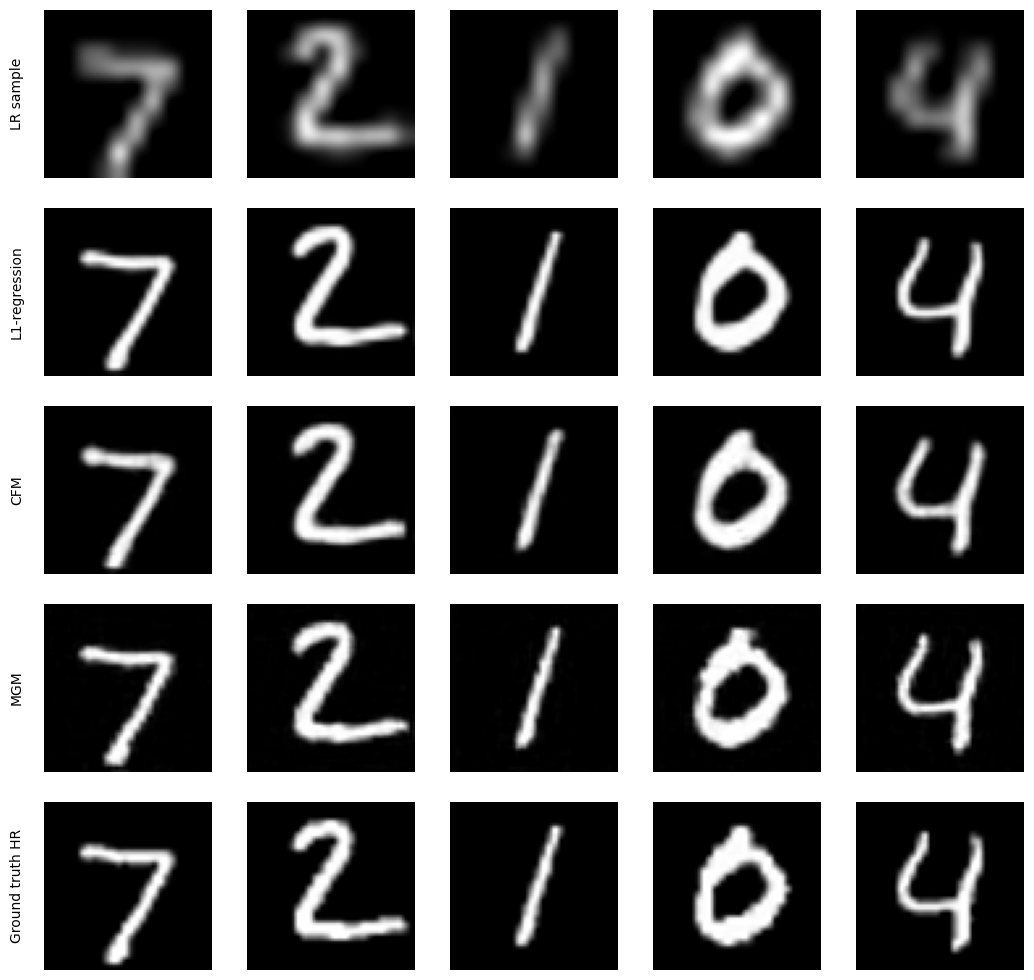

In [37]:

import torch
import matplotlib.pyplot as plt
import numpy as np

@torch.no_grad()
def visualize_sr_comparison(
    val_loader,
    predict_l1,
    predict_cfm,
    predict_mgm,
    device,
    n_samples=5,
):
    # Take the first n_samples from the validation loader
    x_src_list, x_hr_list = [], []

    for x_src, x_hr in val_loader:
        take = min(n_samples - len(x_src_list), x_src.shape[0])
        x_src_list.extend(x_src[:take])
        x_hr_list.extend(x_hr[:take])

        if len(x_src_list) >= n_samples:
            break

    if len(x_src_list) < n_samples:
        raise ValueError(f"Only found {len(x_src_list)} validation samples.")

    x_src = torch.stack(x_src_list).to(device)
    x_hr = torch.stack(x_hr_list).to(device)

    # Generate predictions
    l1_out = predict_l1(x_src).clamp(0, 1)
    cfm_out = predict_cfm(x_src).clamp(0, 1)
    mgm_out = predict_mgm(x_src).clamp(0, 1)

    # Convert [B, 1, H, W] to NumPy images
    def to_numpy(images):
        return images.detach().cpu().squeeze(1).numpy()

    rows = [
        ("LR sample", to_numpy(x_src)),
        ("L1-regression", to_numpy(l1_out)),
        ("CFM", to_numpy(cfm_out)),
        ("MGM", to_numpy(mgm_out)),
        ("Ground truth HR", to_numpy(x_hr)),
    ]

    fig, axes = plt.subplots(
        5, n_samples,
        figsize=(2.2 * n_samples + 1.5, 10),
        squeeze=False,
    )

    for r, (row_label, images) in enumerate(rows):
        for c in range(n_samples):
            ax = axes[r, c]
            ax.imshow(images[c], cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

        # Row label on the left, vertically centered
        axes[r, 0].annotate(
            row_label,
            xy=(-0.12, 0.5),
            xycoords="axes fraction",
            ha="right",
            va="center",
            rotation=90,
            fontsize=10,
            annotation_clip=False,
        )

    plt.subplots_adjust(
        left=0.19, right=0.99, top=0.98, bottom=0.02,
        wspace=0.08, hspace=0.18,
    )
    plt.show()


visualize_sr_comparison(
    val_loader=mnist_val_loader,
    predict_l1=predict_l1,
    predict_cfm=predict_cfm,
    predict_mgm=predict_mgm,
    device=device,
    n_samples=5,
)


In [ ]:
B = BATCH_SIZE
x_src = torch.randn(B, 1, 10, 10, device=device)
x_hr  = torch.randn(B, 1, 64, 64, device=device)
t     = torch.rand(B, device=device)

def count_forward_flops(model, *args):
    """Count supported forward operations for one batch."""
    model = model.to(device).eval()

    with torch.no_grad():
        analysis = FlopCountAnalysis(model, args)
        analysis.unsupported_ops_warnings(False)
        analysis.uncalled_modules_warnings(False)
        total_flops = analysis.total()

    return int(total_flops), analysis

# L1 regression: one forward pass per batch
l1_flops, l1_analysis = count_forward_flops(
    models["L1 regression"], x_src
)

# CFM: count one velocity-field evaluation.
# The time input shape may need adapting to your field implementation.
cfm_flops, cfm_analysis = count_forward_flops(
    models["CFM field"], t, x_hr, x_src
)

print(f"L1 forward FLOPs / batch:  {l1_flops:,}")
print(f"CFM field FLOPs / eval:    {cfm_flops:,}")
print("\nCFM operator coverage:")
print(flop_count_table(cfm_analysis))

In [ ]:
# check that saved

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False,
)

generator_loaded = CelebAUNetGenerator(
    in_channels=1,
    out_channels=1,
    base_channels=32,
).to(device)

generator_ema_loaded = CelebAUNetGenerator(
    in_channels=1,
    out_channels=1,
    base_channels=32,
).to(device)

field_loaded = CelebACriticField(
    in_channels=1,
    out_channels=1,
    base_channels=32,
    time_embedding_dim=64,
).to(device)

generator_loaded.load_state_dict(checkpoint["generator_state_dict"])
generator_ema_loaded.load_state_dict(
    checkpoint["generator_ema_state_dict"]
)
field_loaded.load_state_dict(checkpoint["field_state_dict"])

generator_loaded.eval()
generator_ema_loaded.eval()
field_loaded.eval()

history_loaded = checkpoint["history"]
config_loaded = checkpoint["config"]

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Configuration:", config_loaded)
print("History keys for each epoch:", list(history_loaded[0].keys()))


Loaded checkpoint from epoch: None
Configuration: {'dataset': 'MNIST', 'source_resolution': 10, 'target_resolution': 64, 'channels': 1, 'epochs': 5, 'lr_g': 1e-05, 'lr_f': 1e-05, 'lambda_l1': 0.0, 'eps': 0.01, 'ema_decay': 0.999}
History keys for each epoch: ['epoch', 'global_step', 'loss_f', 'loss_mgm', 'loss_l1', 'loss_g', 'val_l1', 'val_mse', 'val_outside_fraction']


In [ ]:
def diagnose_output_range(model, val_loader, device, model_name="Model"):
    model.eval()

    # Accumulate statistics over the entire validation set.
    total_pixels = 0
    total_abs_raw = 0.0
    total_sq_raw = 0.0
    total_abs_clamped = 0.0
    total_sq_clamped = 0.0

    total_below = 0
    total_above = 0
    total_outside_abs = 0.0

    raw_min = float("inf")
    raw_max = float("-inf")

    with torch.no_grad():
        for x0, x1 in val_loader:
            x0 = x0.to(device)
            x1 = x1.to(device)

            pred = model(x0)

            # Raw predictions: do not clamp.
            pred_raw = pred.float()
            target = x1.float()

            # Predictions clamped to the valid image range.
            pred_clamped = pred_raw.clamp(0.0, 1.0)

            total_pixels += target.numel()

            total_abs_raw += (pred_raw - target).abs().sum().item()
            total_sq_raw += ((pred_raw - target) ** 2).sum().item()

            total_abs_clamped += (
                (pred_clamped - target).abs().sum().item()
            )
            total_sq_clamped += (
                (pred_clamped - target) ** 2
            ).sum().item()

            total_below += (pred_raw < 0.0).sum().item()
            total_above += (pred_raw > 1.0).sum().item()

            total_outside_abs += (
                pred_raw - pred_clamped
            ).abs().sum().item()

            raw_min = min(raw_min, pred_raw.min().item())
            raw_max = max(raw_max, pred_raw.max().item())

    raw_mae = total_abs_raw / total_pixels
    raw_mse = total_sq_raw / total_pixels
    clamped_mae = total_abs_clamped / total_pixels
    clamped_mse = total_sq_clamped / total_pixels

    return {
        "Model": model_name,
        "Raw min": raw_min,
        "Raw max": raw_max,
        "% below 0": 100.0 * total_below / total_pixels,
        "% above 1": 100.0 * total_above / total_pixels,
        "% outside [0,1]": (
            100.0 * (total_below + total_above) / total_pixels
        ),
        "Mean abs overshoot": total_outside_abs / total_pixels,
        "Raw MAE": raw_mae,
        "Clamped MAE": clamped_mae,
        "Raw MSE": raw_mse,
        "Clamped MSE": clamped_mse,
    }


In [ ]:

results = [
    diagnose_output_range(
        generator,
        val_loader,
        device,
        model_name="Generator",
    ),
    diagnose_output_range(
        generator_ema,
        val_loader,
        device,
        model_name="EMA Generator",
    ),
]

diagnostics_df = pd.DataFrame(results).set_index("Model")

display(diagnostics_df.round(6))


,Raw min,Raw max,% below 0,% above 1,"% outside [0,1]",Mean abs overshoot,Raw MAE,Clamped MAE,Raw MSE,Clamped MSE
Model,,,,,,,,,,
Generator,-0.334688,1.304113,44.428079,1.395515,45.823594,0.004493,0.027223,0.022730,0.003661,0.003491
EMA Generator,-0.340668,1.329101,47.958154,1.919817,49.877971,0.004518,0.027942,0.023424,0.003667,0.003525


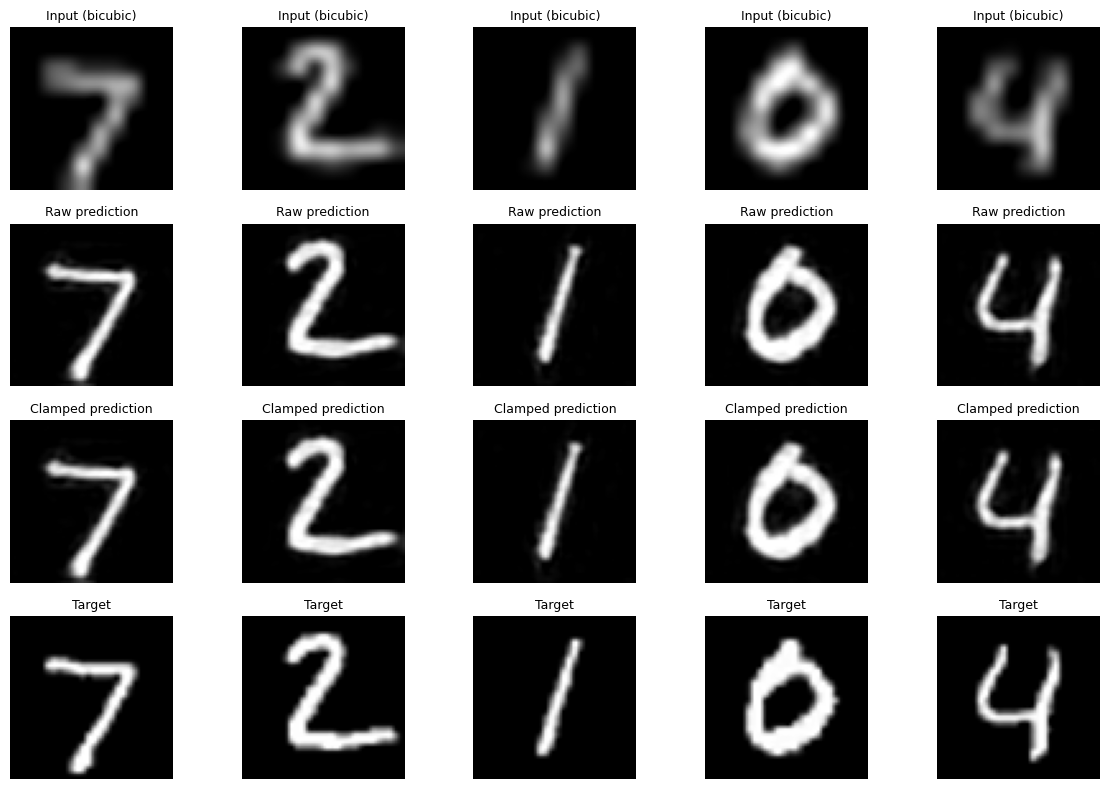

In [ ]:
generator_ema.eval()

x0_batch, x1_batch = next(iter(val_loader))
x0_batch = x0_batch.to(device)
x1_batch = x1_batch.to(device)

with torch.no_grad():
    pred_raw = generator_ema(x0_batch)
    pred_clamped = pred_raw.clamp(0.0, 1.0)

n = min(5, x0_batch.shape[0])

fig, axes = plt.subplots(4, n, figsize=(2.4 * n, 8))

for i in range(n):
    images = [
        (x0_batch[i, 0], "Input (bicubic)"),
        (pred_raw[i, 0], "Raw prediction"),
        (pred_clamped[i, 0], "Clamped prediction"),
        (x1_batch[i, 0], "Target"),
    ]

    for row, (img, title) in enumerate(images):
        # Raw images can have values outside [0,1].
        # Fixing the display range makes them comparable.
        axes[row, i].imshow(
            img.detach().cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row, i].set_title(title, fontsize=9)
        axes[row, i].axis("off")

plt.tight_layout()
plt.show()

#### 2.3) CleebA test

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

generator = CelebAUNetGenerator(
    in_channels=3,
    out_channels=3,
    base_channels=32,
).to(device=device, dtype=torch.float32)

field = CelebACriticField(
    in_channels=3,
    out_channels=3,
    base_channels=32,
    time_embedding_dim=64,
).to(device=device, dtype=torch.float32)

print("Generator parameters:", f"{sum(p.numel() for p in generator.parameters()):,}")
print("Field parameters:", f"{sum(p.numel() for p in field.parameters()):,}")

Using device: cuda
Generator parameters: 1,035,427
Field parameters: 1,176,707


In [ ]:
# Sanity check for models

x_0, x_1 = next(iter(train_loader))

assert x_0.ndim == 4 and x_1.ndim == 4, (
    "Expected image batches with shape [N, C, H, W]."
)
assert x_0.shape == x_1.shape, (
    "For these models, LR images must already be upsampled "
    "to the HR image size."
)
assert x_0.shape[1] == 3, "This configuration expects RGB images."

# Use only two examples for the forward check.
x_0 = x_0[:2].to(device=device, dtype=torch.float32)
x_1 = x_1[:2].to(device=device, dtype=torch.float32)

assert torch.isfinite(x_0).all()
assert torch.isfinite(x_1).all()

with torch.no_grad():
    x_0_hat = generator(x_0)

    N = x_0.shape[0]
    t = torch.full((N,), 0.25, device=device)

    x_tilde = 0.5 * x_0_hat + 0.5 * x_1
    drift = field(t, x_tilde, x_0)

assert x_0_hat.shape == x_1.shape
assert drift.shape == x_1.shape
assert torch.isfinite(x_0_hat).all()
assert torch.isfinite(drift).all()
assert torch.allclose(x_0_hat, x_0, atol=1e-6), (
    "Expected identity initialization from the zero output head."
)

print("Input batch shape:", tuple(x_0.shape))
print("Shape and identity-initialization checks passed.")

del x_0, x_1, x_0_hat, x_tilde, drift, t

Input batch shape: (2, 3, 128, 128)
Shape and identity-initialization checks passed.


In [ ]:
generator, generator_ema, history = train_mgm_celeba(
    generator=generator,
    field=field,
    dataloader=train_loader,
    val_dataloader=val_loader,
    epochs=10,
    lr_g=1e-5,
    lr_f=1e-5,
    lambda_l1=0.0,
    eps=0.01,
    max_grad_norm=1.0,
    ema_decay=0.999,
    device=device,
)

Objective: pure conditional MGM
Paired updates per epoch: 156; each paired update consumes two data batches.
Epoch [1/10] Update [1/156] | F: 0.002306 | MGM: -0.000111 | L1 diagnostic: 0.029400 | Grad F: 0.0790 | Grad G: 0.0711
Epoch [1/10] Update [51/156] | F: 0.001835 | MGM: 0.000205 | L1 diagnostic: 0.029420 | Grad F: 0.0328 | Grad G: 0.0133
Epoch [1/10] Update [101/156] | F: 0.002120 | MGM: 0.000326 | L1 diagnostic: 0.035518 | Grad F: 0.0115 | Grad G: 0.0096
Epoch [1/10] Update [151/156] | F: 0.003827 | MGM: 0.000084 | L1 diagnostic: 0.041273 | Grad F: 0.0307 | Grad G: 0.0100
EMA validation | L1: 0.028197 | MSE: 0.002283 | Outside [0,1]: 2.11%
Epoch [2/10] Update [1/156] | F: 0.004137 | MGM: 0.000149 | L1 diagnostic: 0.042348 | Grad F: 0.0299 | Grad G: 0.0069
Epoch [2/10] Update [51/156] | F: 0.002977 | MGM: 0.000138 | L1 diagnostic: 0.035253 | Grad F: 0.0086 | Grad G: 0.0069
Epoch [2/10] Update [101/156] | F: 0.003284 | MGM: 0.000099 | L1 diagnostic: 0.034564 | Grad F: 0.0097 | Gr

KeyboardInterrupt: 

In [ ]:
# saved_path = save_mgm_checkpoint(
#     generator=trained_generator,
#     descriptor="exp2_10ep_celeba10k_32t128",
#     save_dir=CHECKPOINTS_PATH
# )

Checkpoint successfully saved to: /content/drive/MyDrive/Skoltech/MGM/checkpoints/mgm_exp2_10ep_celeba10k_32t128.pt


Dataset initialized: Loaded 10000 images from local storage.


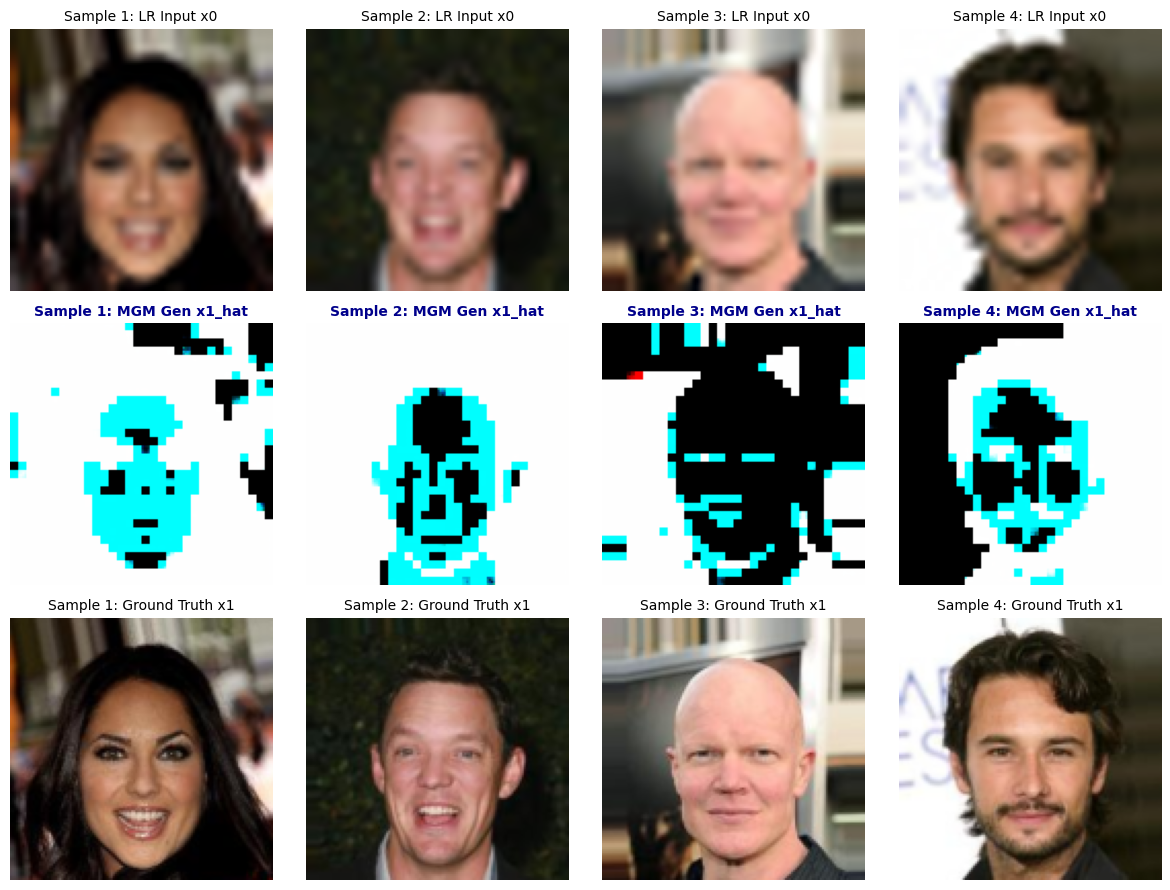

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

test_dataloader = get_celeba_dataloader(batch_size=4, num_samples=10000)
evaluate_and_plot_mgm(trained_generator, test_dataloader, device=device)

#### \inf) Footer buffer -> just stuff...

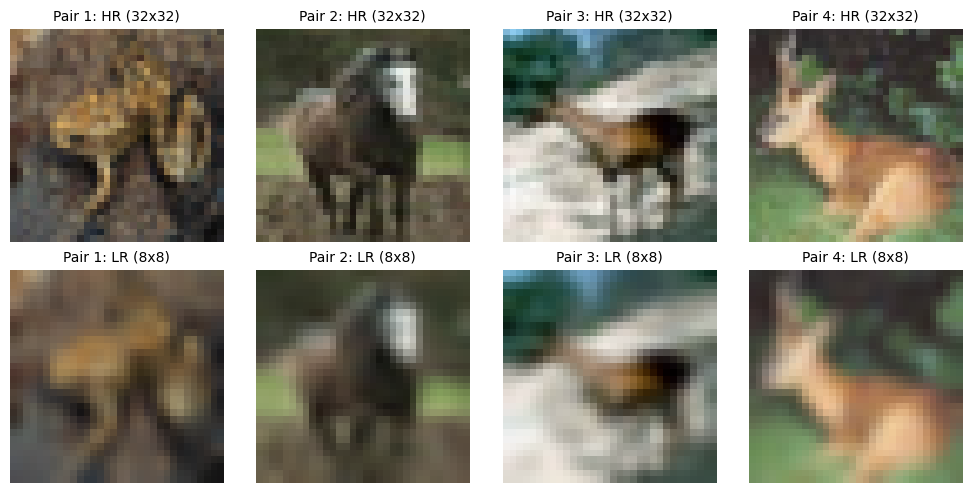

In [ ]:
# 2. Function to un-normalize image tensors from [-1, 1] back to [0, 1]
def unnormalize(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

# 3. Create a 2-row x 4-column subplot grid
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i in range(4):
    # Un-normalize & convert (C, H, W) PyTorch tensor to (H, W, C) for Matplotlib
    hr_img = unnormalize(x1_batch[i]).permute(1, 2, 0).cpu().numpy()
    lr_img = unnormalize(x0_batch[i]).permute(1, 2, 0).cpu().numpy()

    # Row 1: High Resolution (Target x1)
    axes[0, i].imshow(hr_img)
    axes[0, i].set_title(f"Pair {i+1}: HR (32x32)", fontsize=10)
    axes[0, i].axis("off")

    # Row 2: Low Resolution (Input x0)
    axes[1, i].imshow(lr_img)
    axes[1, i].set_title(f"Pair {i+1}: LR (8x8)", fontsize=10)
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()